# Analysis of uoe5 pipeline run
Reran antibody panel 1 with new updates within the pipeline, resutling in run uoe5.

Major pipeline changes include more quality control mesasures focused on organelle channels (lysosome, endosome, and mitochondria) - I added the contrast check that we run for the nuclues channel to script 3 to check each channel before segmentation is preformed. The organelle channels are generally more dim than the nuclues channel, so the threshold for QC is quite a bit lower than that of the nucleus channel.

The goals here are to preform the prior PCA analyses (plus additional analysis on the genotype level, manual focused analsysis, and structure level analysis) and assess whether we reduced the number of poor quality images that make it to this analysis stage. 

In [2]:
import pathlib as Path
import pandas as pd
import os

import glob

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA

In [3]:
uoe5_nucleus_output_fn = "/data/kelpschdj/iNDI/Production/notebooks/analysis_uoe5/uoe5_nucleus_output.parquet"
df = pd.read_parquet(uoe5_nucleus_output_fn)
print(df.head())
print(df.columns.tolist())

   label     area  intensity_mean  intensity_max  intensity_min  \
0      1   4939.0     3642.956266         6248.0         1735.0   
1      2   9671.0     6493.838693        27547.0         1174.0   
2      3   6054.0     4234.435580        10726.0          883.0   
3      4   8794.0      960.669093         1456.0          608.0   
4      5  12435.0     4042.183353        13133.0         1411.0   

   intensity_std   centroid-0   centroid-1  eccentricity  solidity  ...  \
0     891.057838    24.399069  1195.013768      0.842756  0.983277  ...   
1    3302.626429   409.897839  1343.616379      0.729209  0.970302  ...   
2    1676.650264   796.202346   620.880410      0.661181  0.967247  ...   
3     197.895244   964.316579    67.486354      0.575190  0.969036  ...   
4    1584.921888  1000.838118   721.246321      0.713834  0.961122  ...   

   iNDI_Plate_ID      Layout                             Folder_ID  Well_ID  \
0      INDIEC006  PlateEC006  028ebee9-afaf-4ff8-b435-af11714285dc 

In [4]:
print(f"Total number of images: {df[['filename', 'Plate_ID']].drop_duplicates().shape[0]}")
print(f"Total number of nuclei (before QC): {len(df)}")
print(f"Total number of nuclei (after QC): {len(df[df['selected'] == True])}")

Total number of images: 204887
Total number of nuclei (before QC): 1960759
Total number of nuclei (after QC): 991827


In [5]:
group_cols = ["iNDI_Plate_ID", "Gene_Var_Type"]

# "Before" = every nucleus in the table; "after" = only selected.
before = (
    df.groupby(group_cols)
      .agg(images_before=("image_name", "nunique"),
           wells_before=("Well_ID", "nunique"),
           nuclei_before=("image_name", "size"))
)

after = (
    df[df["selected"]]
      .groupby(group_cols)
      .agg(images_after=("image_name", "nunique"),
           wells_after=("Well_ID", "nunique"),
           nuclei_after=("image_name", "size"))
)

summary = (
    before.join(after, how="left")
          .fillna({"images_after": 0, "wells_after": 0, "nuclei_after": 0})
          .astype({"images_after": int, "wells_after": int, "nuclei_after": int})
          .reset_index()
)

# reorder for readability
summary = summary[[
    "iNDI_Plate_ID", "Gene_Var_Type",
    "wells_before", "wells_after",
    "images_before", "images_after",
    "nuclei_before", "nuclei_after",
]]

# print grouped by plate
for plate, grp in summary.groupby("iNDI_Plate_ID"):
    print(f"\n=== iNDI_Plate_ID: {plate} ===")
    print(grp.drop(columns="iNDI_Plate_ID").to_string(index=False))

# summary.to_csv(
#     "/data/kelpschdj/iNDI/Production/outputs/filtering_summary.csv",
#     index=False,
# )
print("Wrote filtering_summary.csv")


=== iNDI_Plate_ID: INDI00002D ===
    Gene_Var_Type  wells_before  wells_after  images_before  images_after  nuclei_before  nuclei_after
 FUS_R495X_REV/WT            48           48           1644          1605          13039          7622
FUS_R495X_SNV/SNV            48           48           1643          1605          14567          7740
 FUS_R495X_SNV/WT            48           48           1666          1644          16749          9176
         KOLF2.1J            96           96           3335          3307          36582         20098
 VCP_R159H_REV/WT            48           48           1367          1250           4540          3134
VCP_R159H_SNV/SNV            48           48           1665          1658          18279         10294
 VCP_R159H_SNV/WT            48           48           1626          1619          20371         10820

=== iNDI_Plate_ID: INDI00007D ===
       Gene_Var_Type  wells_before  wells_after  images_before  images_after  nuclei_before  nuclei_after


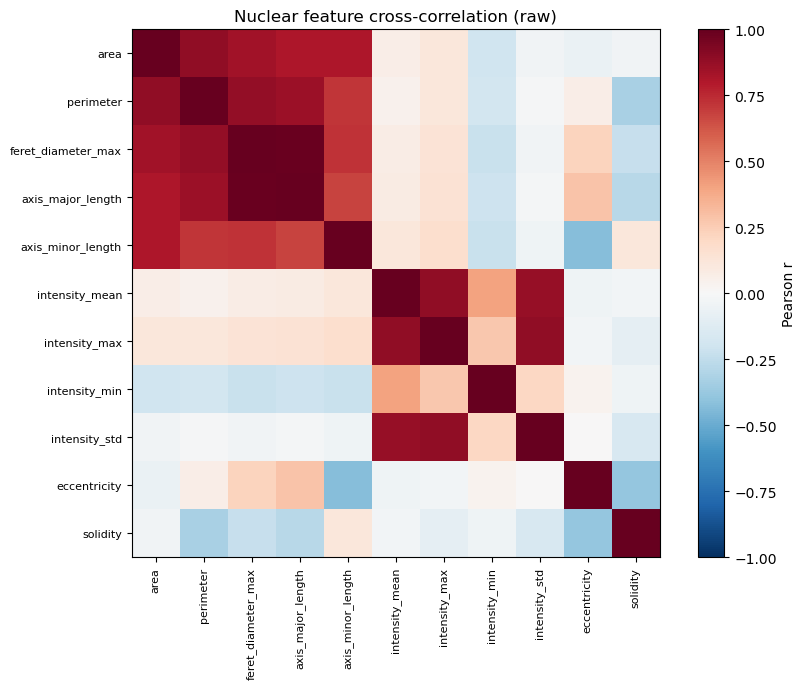

Highly correlated pairs (|r| > 0.9):
  +0.989  feret_diameter_max     axis_major_length

Using FEATURES: ['area', 'intensity_mean', 'intensity_std', 'eccentricity', 'solidity', 'aspect_ratio']


In [6]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA

# df is your merged nuclear-feature dataframe (metadata already joined).

# ---------------------------------------------------------------
# STEP 0 — candidate nuclear features (regionprops from script 1)
# ---------------------------------------------------------------
CANDIDATE_FEATURES = [
    # size
    "area", "perimeter", "feret_diameter_max",
    "axis_major_length", "axis_minor_length",
    # intensity (DAPI)
    "intensity_mean", "intensity_max", "intensity_min", "intensity_std",
    # shape
    "eccentricity", "solidity",
]
CANDIDATE_FEATURES = [c for c in CANDIDATE_FEATURES if c in df.columns]

# ---------------------------------------------------------------
# STEP 1 — cross-correlation (raw, pre-scaling)
# ---------------------------------------------------------------
X_all = df[CANDIDATE_FEATURES].replace([np.inf, -np.inf], np.nan)
corr = X_all.corr(method="pearson")

plt.figure(figsize=(9, 7))
im = plt.imshow(corr, cmap="RdBu_r", vmin=-1, vmax=1)
plt.xticks(range(len(CANDIDATE_FEATURES)), CANDIDATE_FEATURES, rotation=90, fontsize=8)
plt.yticks(range(len(CANDIDATE_FEATURES)), CANDIDATE_FEATURES, fontsize=8)
plt.colorbar(im, label="Pearson r")
plt.title("Nuclear feature cross-correlation (raw)")
plt.tight_layout(); plt.show()

hi = (corr.abs() > 0.9) & (corr.abs() < 1.0)
pairs = [
    (a, b, round(corr.loc[a, b], 3))
    for i, a in enumerate(CANDIDATE_FEATURES)
    for b in CANDIDATE_FEATURES[i + 1:]
    if hi.loc[a, b]
]
print("Highly correlated pairs (|r| > 0.9):")
for a, b, r in sorted(pairs, key=lambda t: -abs(t[2])):
    print(f"  {r:+.3f}  {a:22s} {b}")

# ---------------------------------------------------------------
# STEP 2 — pruned FEATURES
# The size cluster (area, perimeter, feret, both axes) is heavily collinear.
# Keep `area` as the size representative + a shape-aspect ratio that captures
# elongation independent of size. Drop the redundant size columns.
# ---------------------------------------------------------------
df["aspect_ratio"] = df["axis_minor_length"] / df["axis_major_length"]

FEATURES = [
    "area",
    "intensity_mean", "intensity_std",
    "eccentricity", "solidity", "aspect_ratio",
]
FEATURES = [c for c in FEATURES if c in df.columns]
print("\nUsing FEATURES:", FEATURES)

Dropped 0 rows with NaN/inf; 1960759 remain


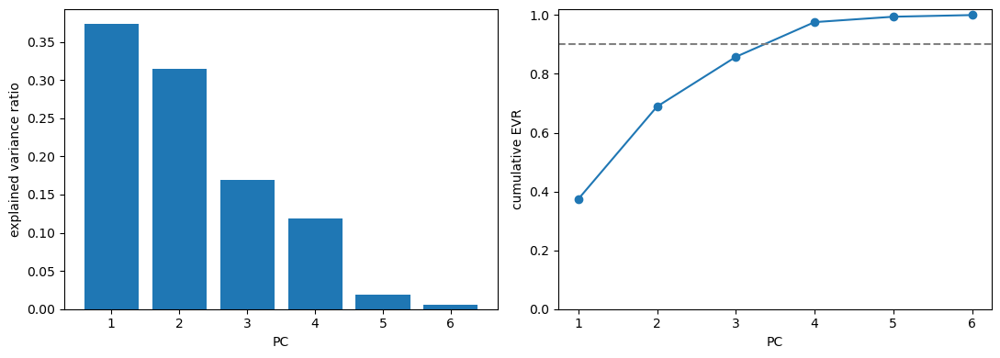

EVR: [0.374 0.315 0.169 0.118 0.018 0.006]
cumulative: [0.374 0.689 0.858 0.976 0.994 1.   ]
                  PC1    PC2    PC3    PC4    PC5    PC6
area            0.049  0.035  0.976  0.190  0.084  0.008
intensity_mean -0.025  0.701  0.004  0.164 -0.694  0.001
intensity_std  -0.086  0.699 -0.079 -0.010  0.706  0.001
eccentricity   -0.630 -0.090 -0.036  0.329  0.011  0.697
solidity        0.428 -0.073 -0.197  0.870  0.115 -0.045
aspect_ratio    0.640  0.080  0.012 -0.268 -0.005  0.716


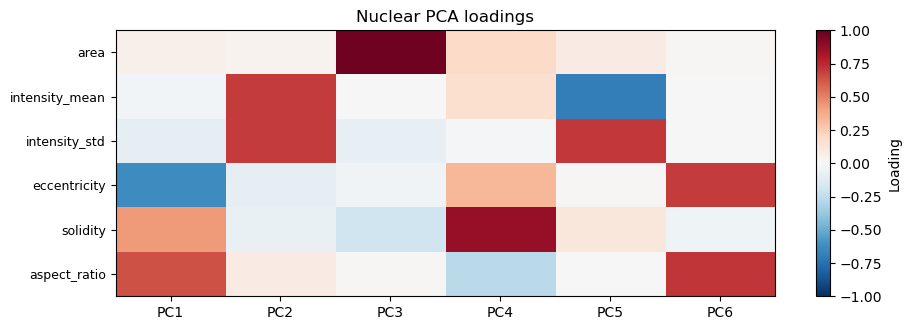

In [7]:
# ---------------------------------------------------------------
# NaN/inf handling
# ---------------------------------------------------------------
before = len(df)
X_df = df[FEATURES].replace([np.inf, -np.inf], np.nan)
keep = X_df.notna().all(axis=1)
df = df[keep].reset_index(drop=True)
X_df = X_df[keep].reset_index(drop=True)
print(f"Dropped {before - len(df)} rows with NaN/inf; {len(df)} remain")

# ---------------------------------------------------------------
# scale + PCA
# ---------------------------------------------------------------
X = StandardScaler().fit_transform(X_df.values)
pca = PCA(n_components=len(FEATURES))
scores = pca.fit_transform(X)
for i in range(scores.shape[1]):
    df[f"PC{i+1}"] = scores[:, i]

# scree
ev = pca.explained_variance_ratio_
fig, ax = plt.subplots(1, 2, figsize=(11, 4))
ax[0].bar(range(1, len(ev) + 1), ev)
ax[0].set_xlabel("PC"); ax[0].set_ylabel("explained variance ratio")
ax[1].plot(range(1, len(ev) + 1), np.cumsum(ev), marker="o")
ax[1].axhline(0.9, ls="--", c="gray"); ax[1].set_xlabel("PC")
ax[1].set_ylabel("cumulative EVR"); ax[1].set_ylim(0, 1.02)
plt.tight_layout(); plt.show()
print("EVR:", ev.round(3))
print("cumulative:", np.cumsum(ev).round(3))

# loadings
loadings = pd.DataFrame(
    pca.components_.T, index=FEATURES,
    columns=[f"PC{i+1}" for i in range(len(FEATURES))],
)
print(loadings.round(3))

n_show = min(6, len(FEATURES))
plt.figure(figsize=(1.6 * n_show, 0.4 * len(FEATURES) + 1))
im = plt.imshow(loadings.iloc[:, :n_show], cmap="RdBu_r", vmin=-1, vmax=1, aspect="auto")
plt.xticks(range(n_show), [f"PC{i+1}" for i in range(n_show)])
plt.yticks(range(len(FEATURES)), FEATURES, fontsize=9)
plt.colorbar(im, label="Loading")
plt.title("Nuclear PCA loadings")
plt.tight_layout(); plt.show()

21 plates in this run:
['INDI00002D', 'INDI00007D', 'INDI00011D', 'INDI00015D', 'INDI00019D', 'INDI00023D', 'INDI00026D', 'INDI00035D', 'INDI00039D', 'INDI00043D', 'INDI00047D', 'INDI00049D', 'INDI00053D', 'INDIEC006', 'INDIEC007', 'INDIEL001', 'INDIEL002', 'INDIEL003', 'INDIMS004', 'INDIMS005', 'INDIRK008']
All 21 plates have a color.


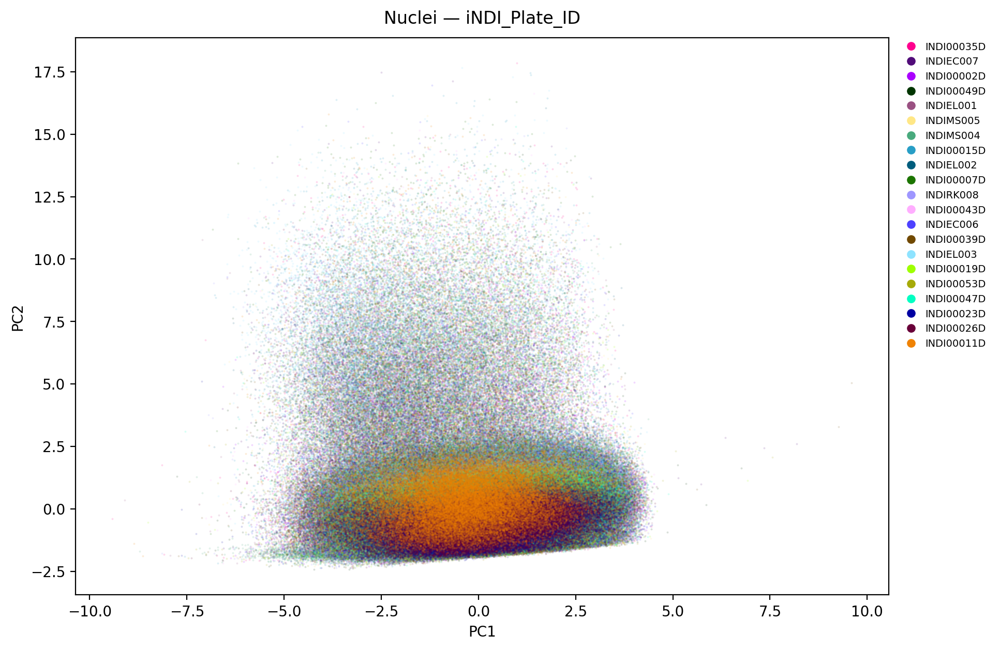

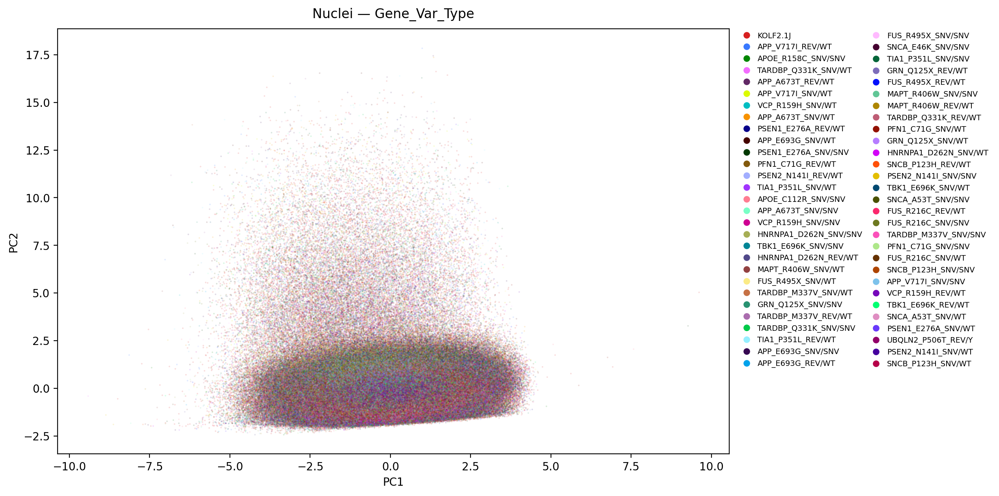

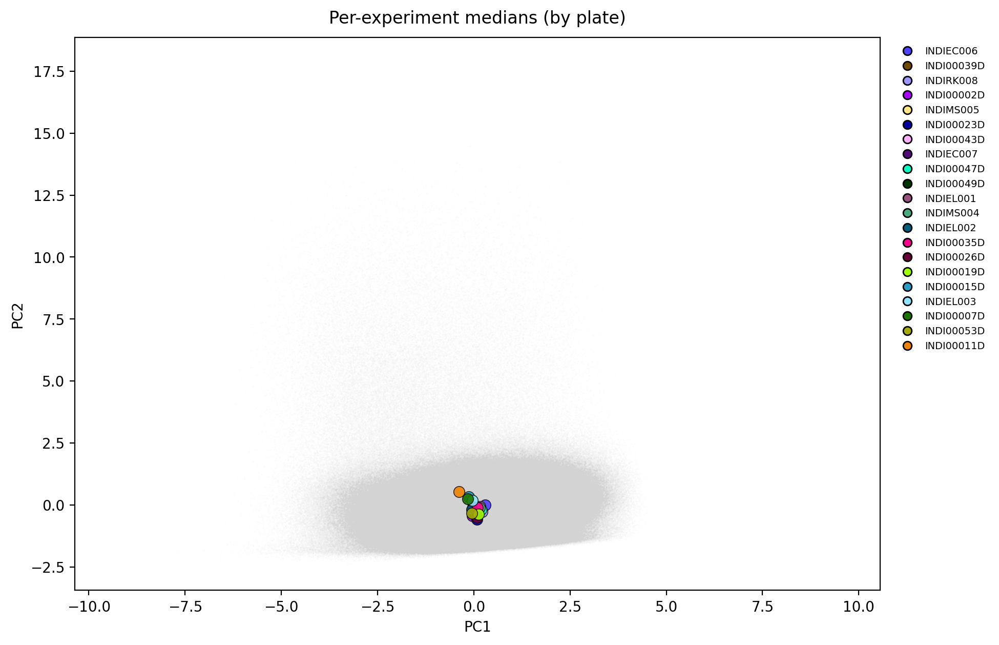

Std of per-experiment centroids (batch magnitude):
PC1    0.149
PC2    0.278
PC3    0.131
dtype: float64


In [8]:
from matplotlib.lines import Line2D
from matplotlib.colors import ListedColormap
import seaborn as sns
import glasbey

import glasbey
from matplotlib.colors import ListedColormap

# derive plate list from the data, not a hardcoded set
unique_plate_ids = sorted(df["iNDI_Plate_ID"].dropna().unique())
print(f"{len(unique_plate_ids)} plates in this run:")
print(unique_plate_ids)

plate_palette_raw = glasbey.create_palette(
    palette_size=max(len(unique_plate_ids), 1),
    hue_bounds=(60, 500.0), chroma_bounds=(40, 130),
)
colors_plates = [ListedColormap(plate_palette_raw)(i)
                 for i in range(len(plate_palette_raw))]
plate_palette = {pid: colors_plates[i] for i, pid in enumerate(unique_plate_ids)}

# glasbey palette for genotypes (high-cardinality, no fixed mapping)
geno_palette_raw = glasbey.create_palette(
    palette_size=64, hue_bounds=(0.0, 360.0), chroma_bounds=(40, 90)
)
geno_colors = [ListedColormap(geno_palette_raw)(i)
               for i in range(len(geno_palette_raw))]

def pca_scatter(df, color_col, pcx="PC1", pcy="PC2", palette=None,
                s=2, alpha=0.15, figsize=(10, 7), legend_ncol=1,
                title=None, show_legend=True):
    fig, ax = plt.subplots(figsize=figsize, dpi=200)
    fig.subplots_adjust(right=0.78)
    vals = df[color_col].astype("object")
    cats = vals.value_counts().index.tolist()

    if palette is not None:
        colors = [palette.get(c, "#808080") for c in cats]
    elif color_col == "Gene_Var_Type":
        colors = [geno_colors[i % len(geno_colors)] for i in range(len(cats))]
    else:
        colors = sns.color_palette("husl", n_colors=len(cats))

    for c, col in zip(cats, colors):
        m = vals == c
        ax.scatter(df.loc[m, pcx], df.loc[m, pcy], s=s, alpha=alpha,
                   color=col, linewidths=0, rasterized=True)
    ax.set_xlabel(pcx); ax.set_ylabel(pcy)
    ax.set_title(title or f"PCA of {color_col}", pad=10)
    if show_legend:
        handles = [Line2D([0], [0], marker="o", linestyle="", markersize=5,
                   markerfacecolor=col, markeredgecolor=col, label=str(c))
                   for c, col in zip(cats, colors)]
        ax.legend(handles=handles, loc="upper left", bbox_to_anchor=(1.01, 1.0),
                  frameon=False, fontsize=7, ncol=legend_ncol,
                  borderaxespad=0.0, handletextpad=0.4, columnspacing=0.8)
    plt.show()


# guard: plates in data with no palette color
plates_in_data = set(df["iNDI_Plate_ID"].dropna().unique())
missing = plates_in_data - set(plate_palette)
print(f"[warning] plates with no color: {sorted(missing)}" if missing
      else f"All {len(plates_in_data)} plates have a color.")

df_shuf = df.sample(frac=1, random_state=0).reset_index(drop=True)
pca_scatter(df_shuf, "iNDI_Plate_ID", palette=plate_palette, figsize=(12, 7),
            title="Nuclei — iNDI_Plate_ID")
pca_scatter(df_shuf, "Gene_Var_Type", figsize=(13, 7), legend_ncol=2,
            title="Nuclei — Gene_Var_Type")

def centroid_overlay(df, color_col, group_keys, pcx="PC1", pcy="PC2",
                     palette=None, stat="median", bg_frac=1.0, s_centroid=60,
                     figsize=(10, 7), legend_ncol=1, title=None,
                     bg_s=1, bg_alpha=0.03):
    fig, ax = plt.subplots(figsize=figsize, dpi=200)
    fig.subplots_adjust(right=0.78)
    bg = df.sample(frac=bg_frac, random_state=0) if bg_frac < 1.0 else df
    ax.scatter(bg[pcx], bg[pcy], s=bg_s, alpha=bg_alpha, color="lightgray",
               linewidths=0, rasterized=True)
    agg_spec = {pcx: stat, pcy: stat}
    if color_col not in group_keys:
        agg_spec[color_col] = "first"
    cent = df.groupby(group_keys).agg(agg_spec).reset_index()
    vals = cent[color_col].astype("object")
    cats = vals.value_counts().index.tolist()
    if palette is not None:
        colors = [palette.get(c, "#808080") for c in cats]
    else:
        colors = sns.color_palette("husl", n_colors=len(cats))
    for c, col in zip(cats, colors):
        m = vals == c
        ax.scatter(cent.loc[m, pcx], cent.loc[m, pcy], s=s_centroid, color=col,
                   edgecolor="k", linewidths=0.5, alpha=0.9)
    ax.set_xlabel(pcx); ax.set_ylabel(pcy)
    ax.set_title(title or f"Per-group {stat} centroids ({color_col})", pad=10)
    handles = [Line2D([0], [0], marker="o", linestyle="", markersize=6,
               markerfacecolor=col, markeredgecolor="k", label=str(c))
               for c, col in zip(cats, colors)]
    ax.legend(handles=handles, loc="upper left", bbox_to_anchor=(1.01, 1.0),
              frameon=False, fontsize=7, ncol=legend_ncol)
    plt.show()
    return cent

# per-experiment medians, colored by plate — spread = batch variation
centroid_overlay(df, color_col="iNDI_Plate_ID", group_keys=["Measurement_ID"],
                 palette=plate_palette, title="Per-experiment medians (by plate)",
                 figsize=(12, 7))

# batch magnitude: std of per-experiment centroids (no Structure split now)
cent = df.groupby("Measurement_ID")[["PC1", "PC2", "PC3"]].median()
print("Std of per-experiment centroids (batch magnitude):")
print(cent.std().round(3))

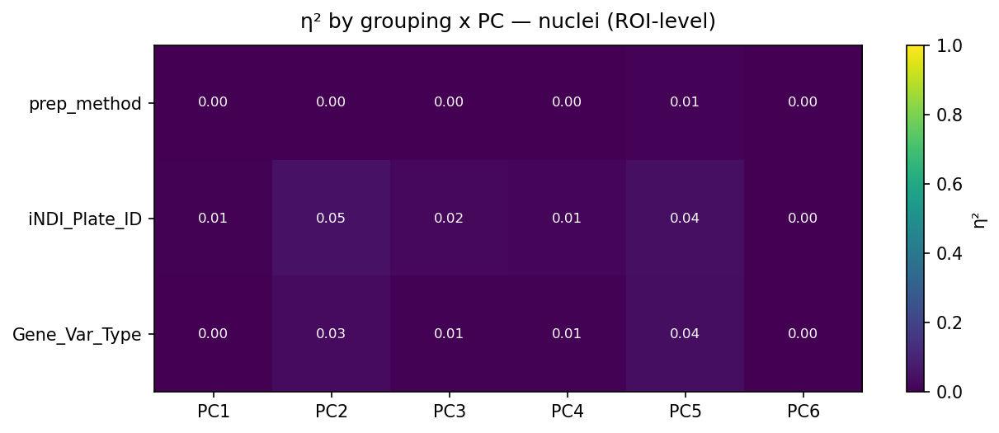

In [9]:
def eta_squared(values, groups):
    values = np.asarray(values, dtype=float)
    mask = np.isfinite(values)
    values, groups = values[mask], np.asarray(groups)[mask]
    if values.size == 0:
        return np.nan
    grand = values.mean()
    ss_total = ((values - grand) ** 2).sum()
    ss_between = 0.0
    for g in pd.unique(groups):
        v = values[groups == g]
        if v.size == 0:            # guard: skip empty groups
            continue
        ss_between += len(v) * (v.mean() - grand) ** 2
    return ss_between / ss_total if ss_total > 0 else np.nan


def eta_heatmap(data, group_cols, n_pcs=None, title="η² by grouping x PC", annot=True):
    pc_cols = sorted([c for c in data.columns if c.startswith("PC")],
                     key=lambda s: int(s[2:]))
    if n_pcs is not None:
        pc_cols = pc_cols[:n_pcs]
    group_cols = [g for g in group_cols if g in data.columns]
    mat = pd.DataFrame(index=group_cols, columns=pc_cols, dtype=float)
    for gc in group_cols:
        groups = data[gc].to_numpy()
        for pc in pc_cols:
            mat.loc[gc, pc] = eta_squared(data[pc].to_numpy(), groups)
    fig, ax = plt.subplots(figsize=(1.1 * len(pc_cols) + 2, 0.7 * len(group_cols) + 1.5), dpi=150)
    im = ax.imshow(mat.values.astype(float), cmap="viridis", vmin=0, vmax=1, aspect="auto")
    ax.set_xticks(range(len(pc_cols))); ax.set_xticklabels(pc_cols)
    ax.set_yticks(range(len(group_cols))); ax.set_yticklabels(group_cols)
    plt.colorbar(im, ax=ax, label="η²")
    ax.set_title(title, pad=10)
    if annot:
        for i in range(len(group_cols)):
            for j in range(len(pc_cols)):
                v = mat.iloc[i, j]
                if pd.notna(v):
                    ax.text(j, i, f"{v:.2f}", ha="center", va="center",
                            color="white" if v < 0.6 else "black", fontsize=8)
    plt.tight_layout(); plt.show()
    return mat

# Structure dropped (single channel). Batch drivers that matter for nuclei:
GROUP_COLS = ["prep_method", "iNDI_Plate_ID", "Gene_Var_Type"]
eta_full = eta_heatmap(df, GROUP_COLS, n_pcs=6, title="η² by grouping x PC — nuclei (ROI-level)")

Genotype_Name: 0 well(s) with >1 value
iNDI_Plate_ID: 0 well(s) with >1 value
prep_method: 0 well(s) with >1 value

Image-level: 204887 rows (13440 images)
Well-level: 6357 rows
Well-level EVR: [0.374 0.299 0.164 0.127 0.032 0.004] | cumulative: [0.374 0.673 0.837 0.964 0.996 1.   ]


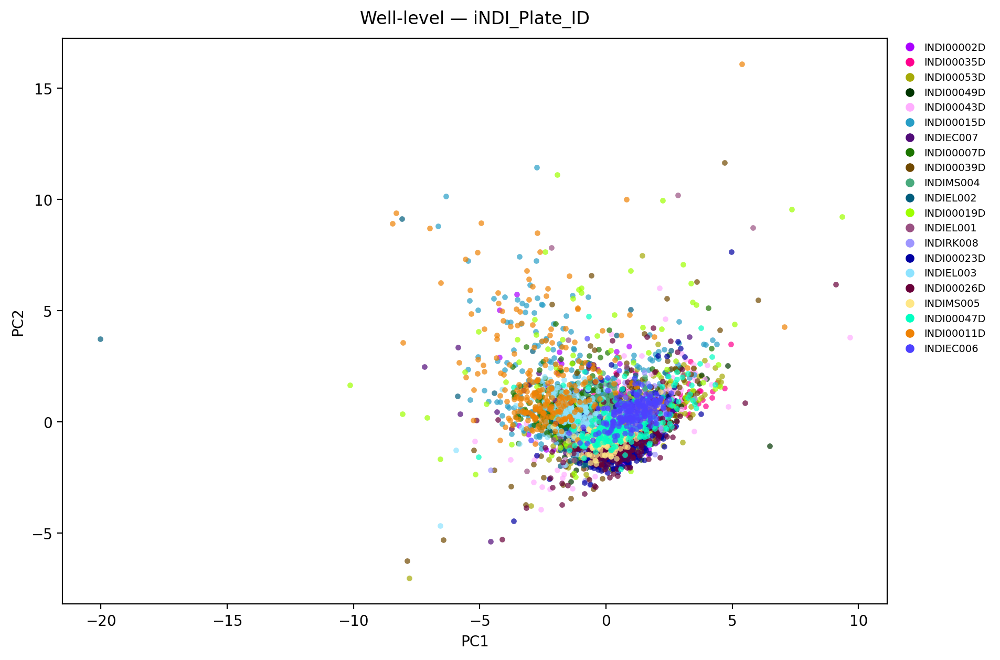

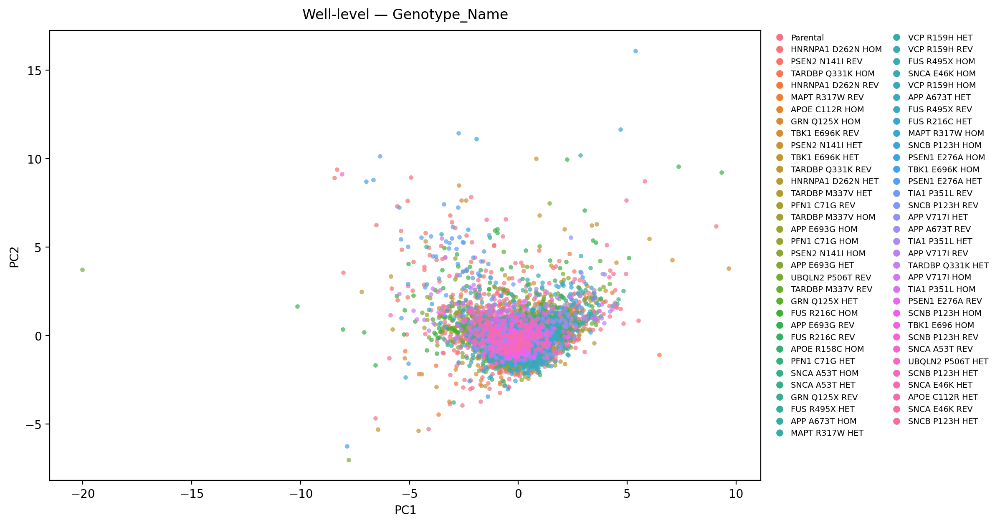

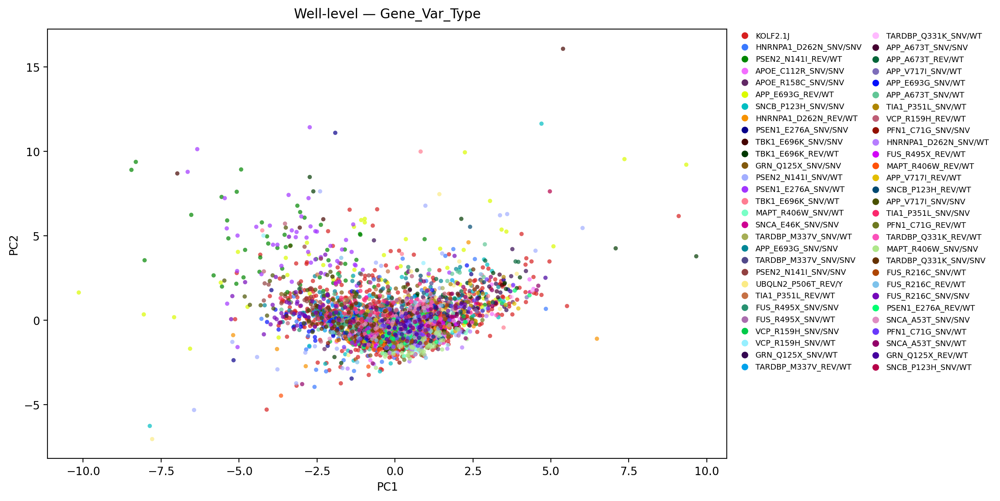

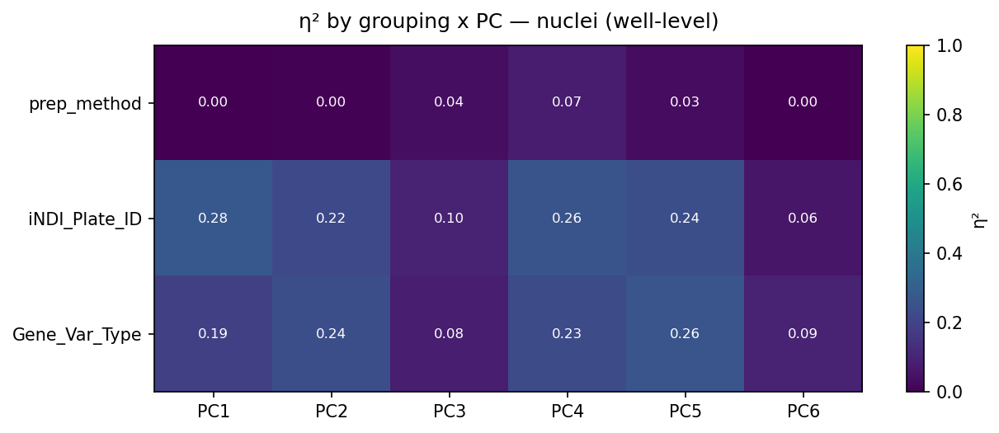

,PC1,PC2,PC3,PC4,PC5,PC6
prep_method,0.001916,0.004419,0.038503,0.074264,0.033845,0.001779
iNDI_Plate_ID,0.276734,0.221540,0.096524,0.261694,0.241753,0.059828
Gene_Var_Type,0.188705,0.242169,0.084996,0.227293,0.262702,0.094673


In [10]:
# Nuclei keys: image = image_name, well = Measurement_ID + subdirectory.
# No Structure grouping.
WELL_KEYS = ["Measurement_ID", "subdirectory"]
IMAGE_KEY = "image_name"

GROUP_KEYS = [*WELL_KEYS, IMAGE_KEY]
DROP_COLS = set(FEATURES) | {f"PC{i+1}" for i in range(20)} | set(GROUP_KEYS) \
            | {"label", "filename", "filepath"}
META_COLS = [c for c in df.columns if c not in DROP_COLS]

# safety: metadata carried by .first() should be invariant within a well
for col in ["Genotype_Name", "iNDI_Plate_ID", "prep_method"]:
    if col in df.columns:
        n_bad = (df.groupby(WELL_KEYS)[col].nunique() > 1).sum()
        print(f"{col}: {n_bad} well(s) with >1 value{'  <-- CHECK' if n_bad else ''}")

# stage 1: median across nuclei within each image
agg_image = {**{f: "median" for f in FEATURES}, **{m: "first" for m in META_COLS}}
image_level = df.groupby(GROUP_KEYS, as_index=False).agg(agg_image)
print(f"\nImage-level: {len(image_level)} rows ({df[IMAGE_KEY].nunique()} images)")

# stage 2: mean across images within each well
agg_well = {**{f: "mean" for f in FEATURES}, **{m: "first" for m in META_COLS}}
well_level = image_level.groupby(WELL_KEYS, as_index=False).agg(agg_well)
print(f"Well-level: {len(well_level)} rows")

# refit PCA on well-level profiles
Xw_df = well_level[FEATURES].replace([np.inf, -np.inf], np.nan)
keep = Xw_df.notna().all(axis=1)
well_level = well_level[keep].reset_index(drop=True)
Xw_df = Xw_df[keep].reset_index(drop=True)
Xw = StandardScaler().fit_transform(Xw_df.values)
pca_well = PCA(n_components=len(FEATURES))
scores_w = pca_well.fit_transform(Xw)
for i in range(scores_w.shape[1]):
    well_level[f"PC{i+1}"] = scores_w[:, i]
evw = pca_well.explained_variance_ratio_
print("Well-level EVR:", evw.round(3), "| cumulative:", np.cumsum(evw).round(3))

well_shuf = well_level.sample(frac=1, random_state=0).reset_index(drop=True)
pca_scatter(well_shuf, "iNDI_Plate_ID", palette=plate_palette, s=15, alpha=0.7,
            figsize=(12, 7), title="Well-level — iNDI_Plate_ID")
pca_scatter(well_shuf, "Genotype_Name", s=15, alpha=0.7, figsize=(13, 7),
            legend_ncol=2, title="Well-level — Genotype_Name")
pca_scatter(well_shuf, "Gene_Var_Type", s=15, alpha=0.7, figsize=(13, 7),
            legend_ncol=2, title="Well-level — Gene_Var_Type")

# well-level η² (does plate structure persist after aggregation?)
eta_heatmap(well_level, ["prep_method", "iNDI_Plate_ID", "Gene_Var_Type"],
            n_pcs=6, title="η² by grouping x PC — nuclei (well-level)")

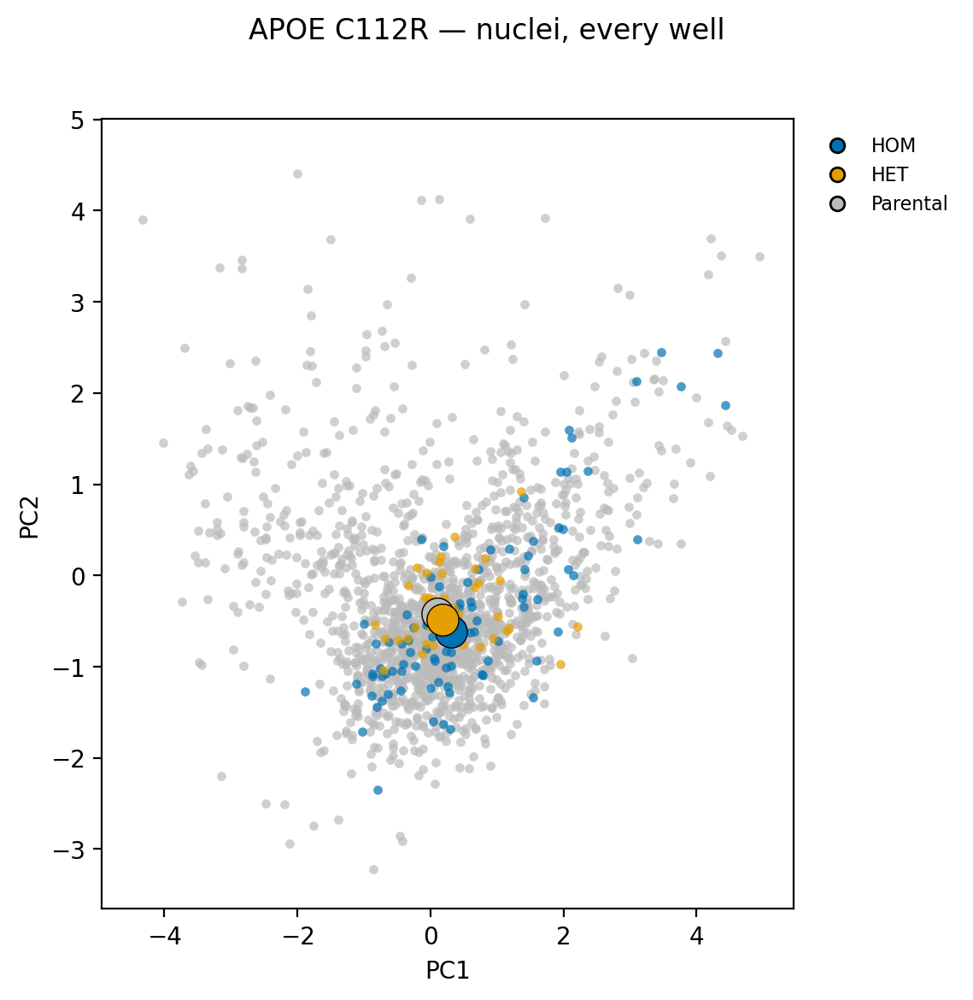

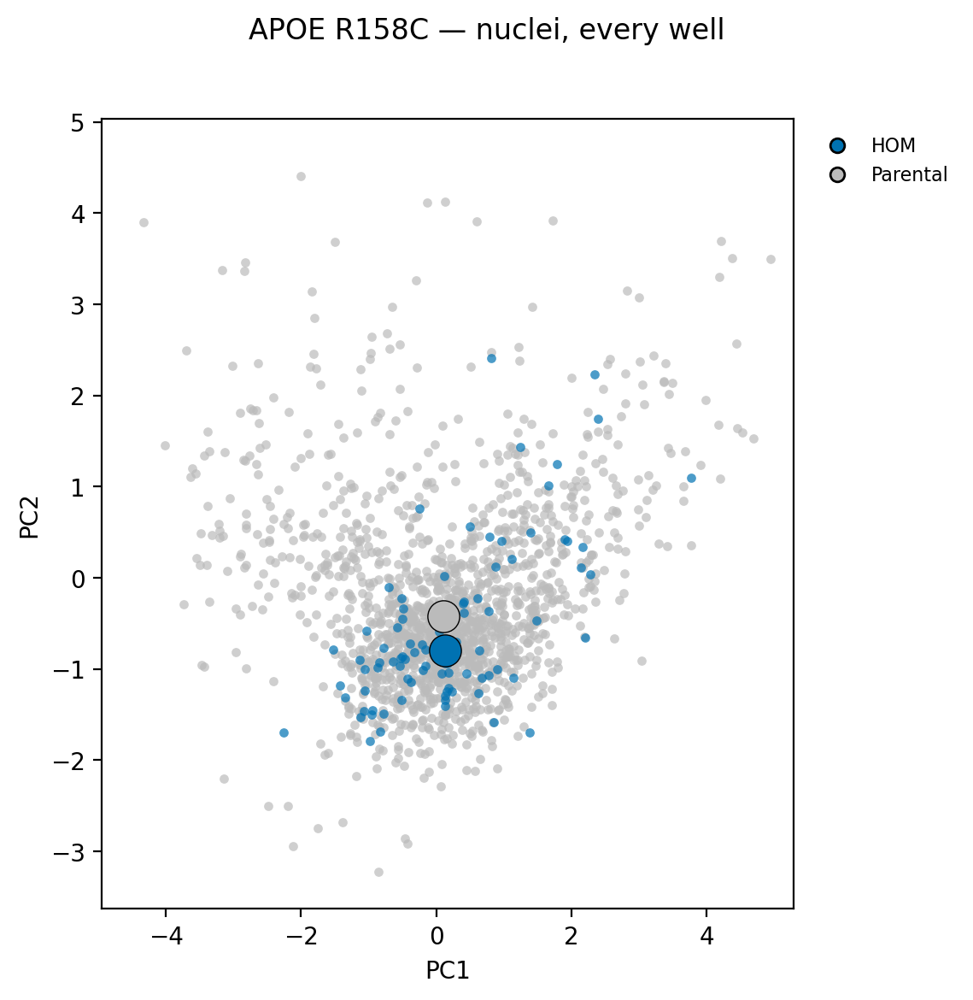

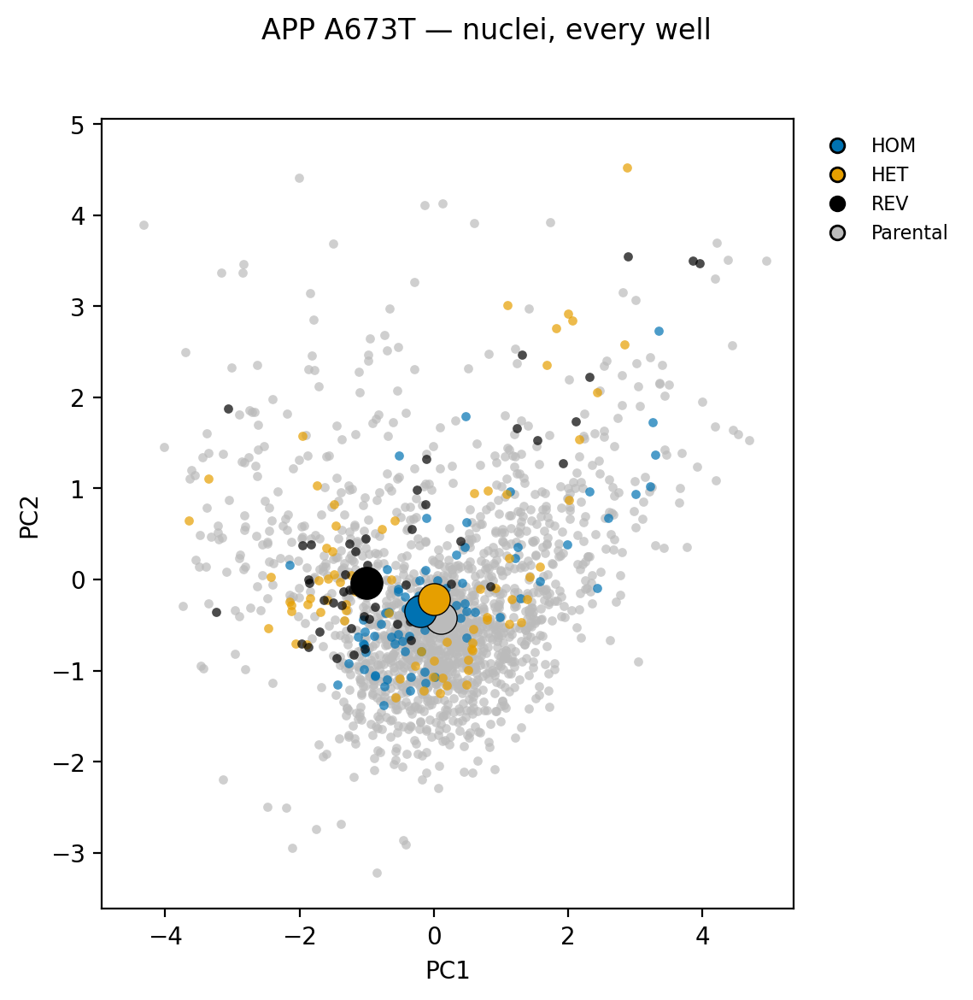

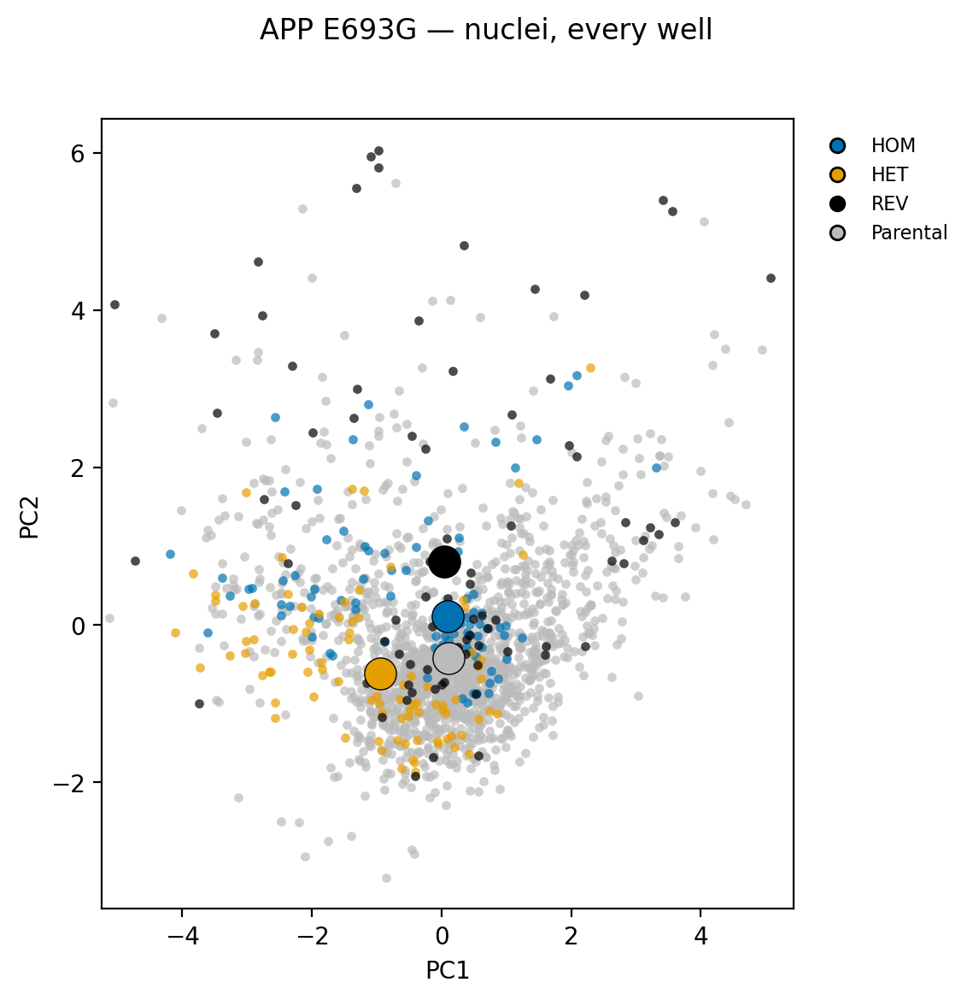

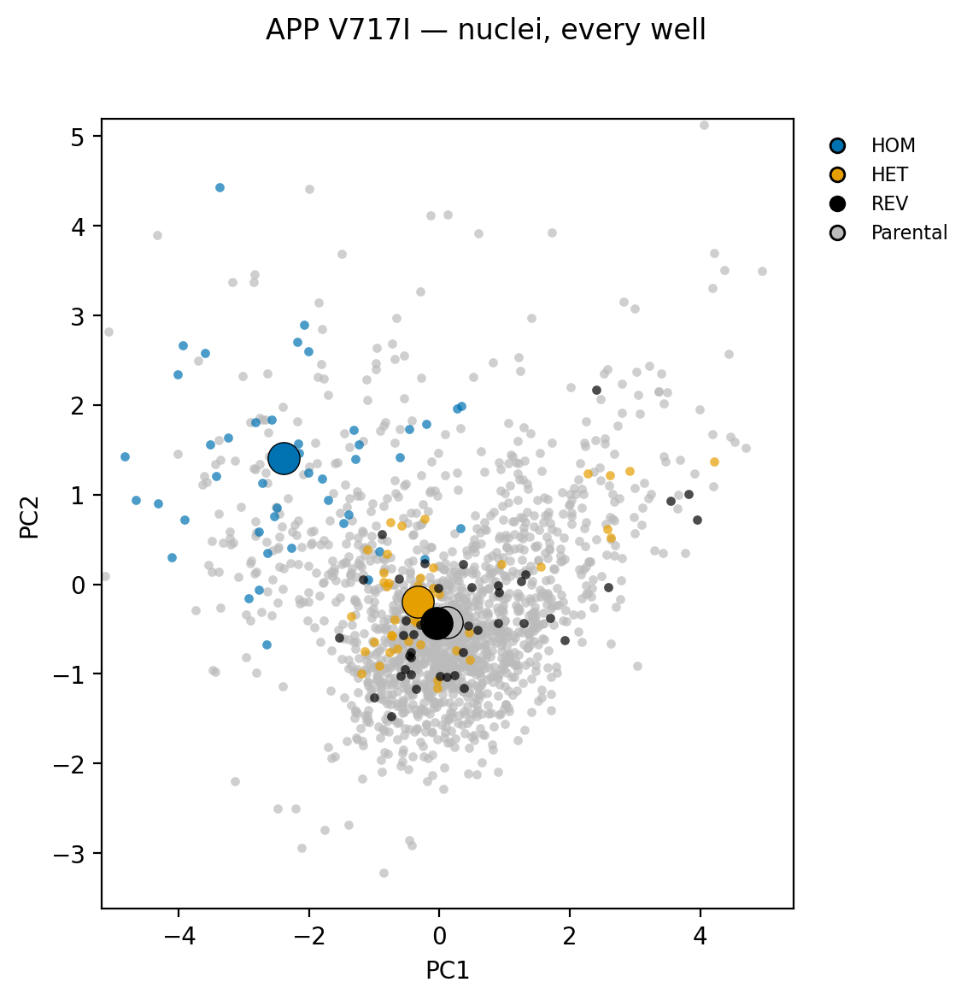

...

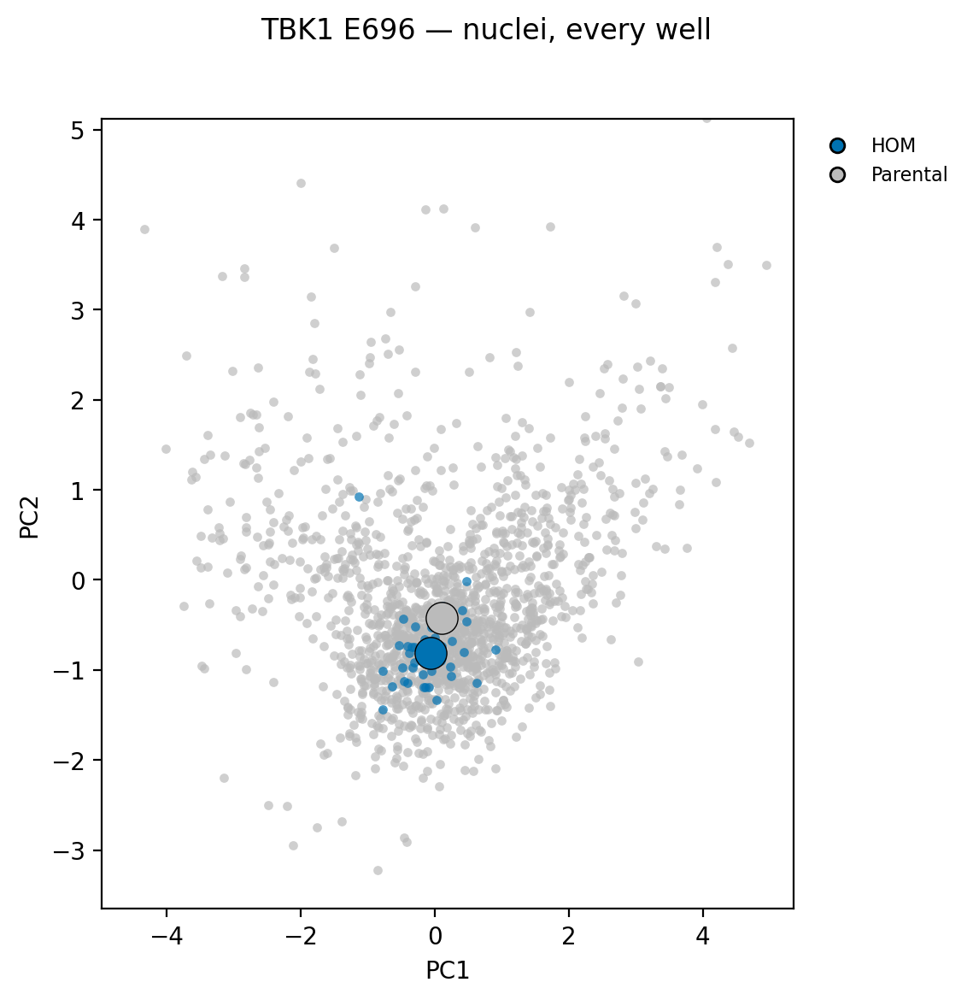

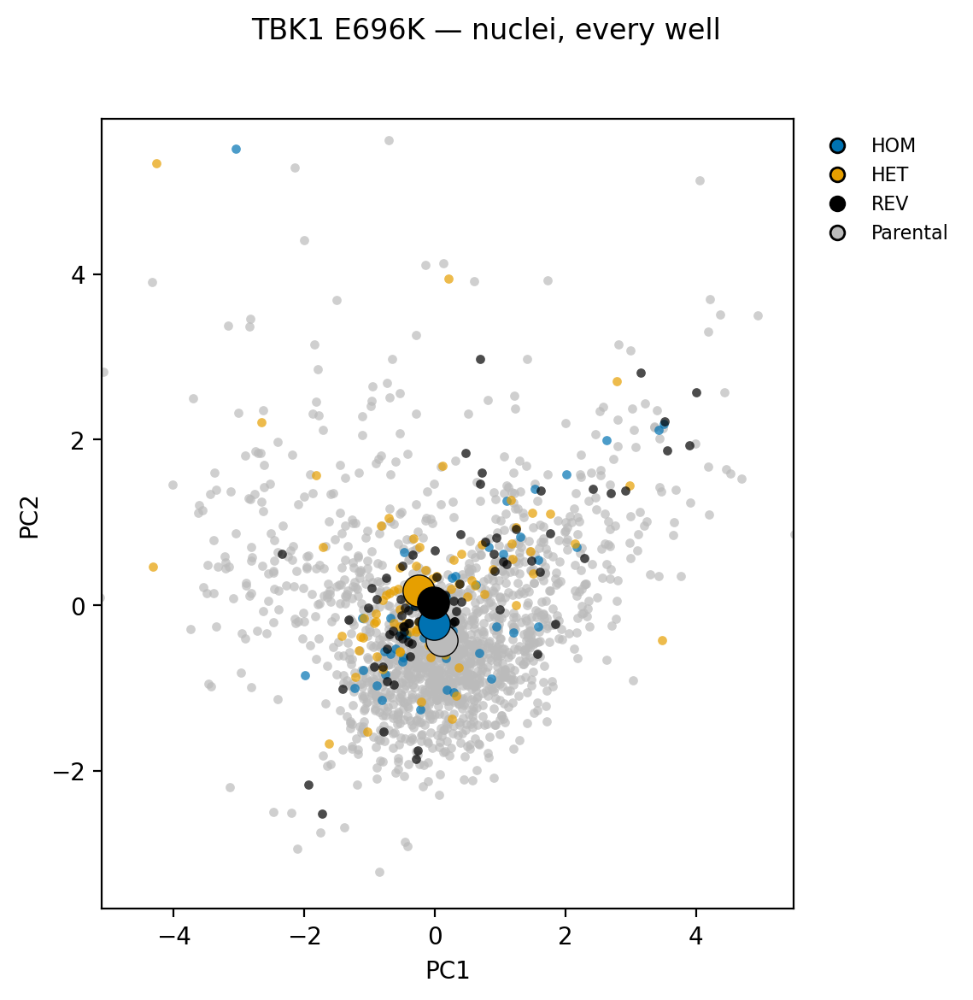

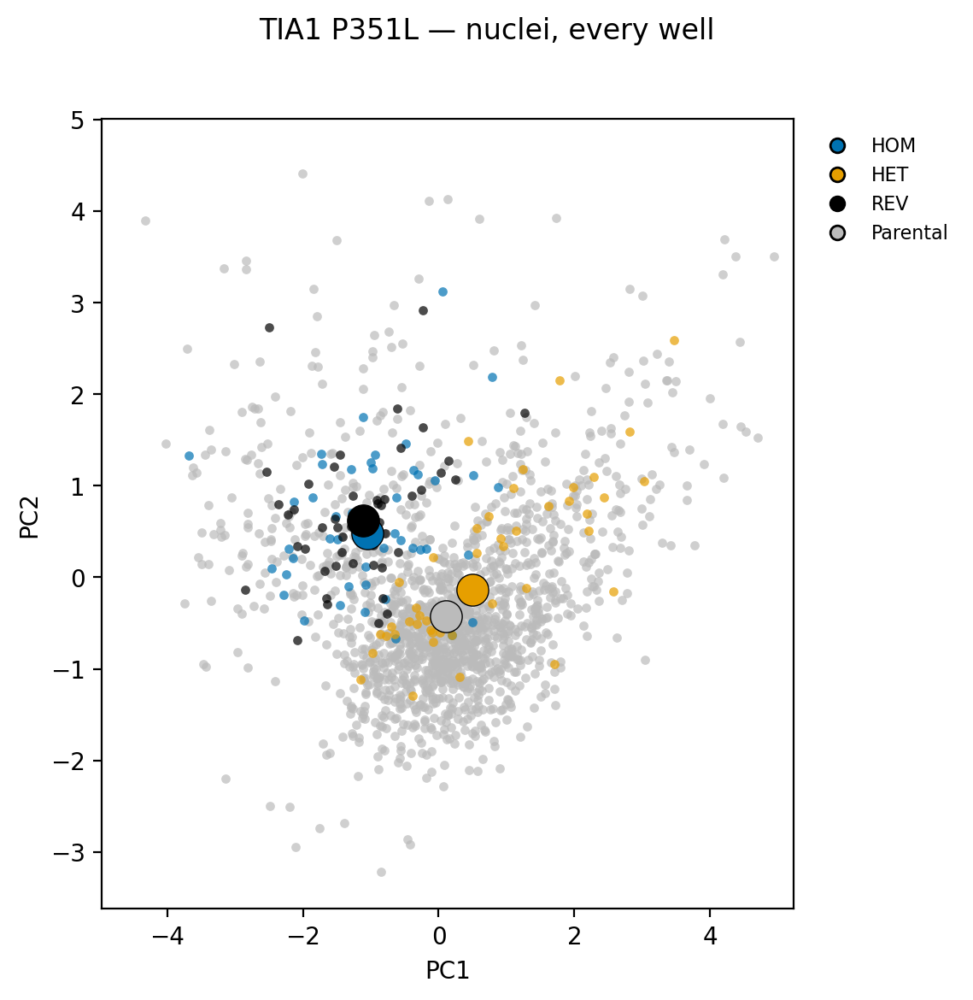

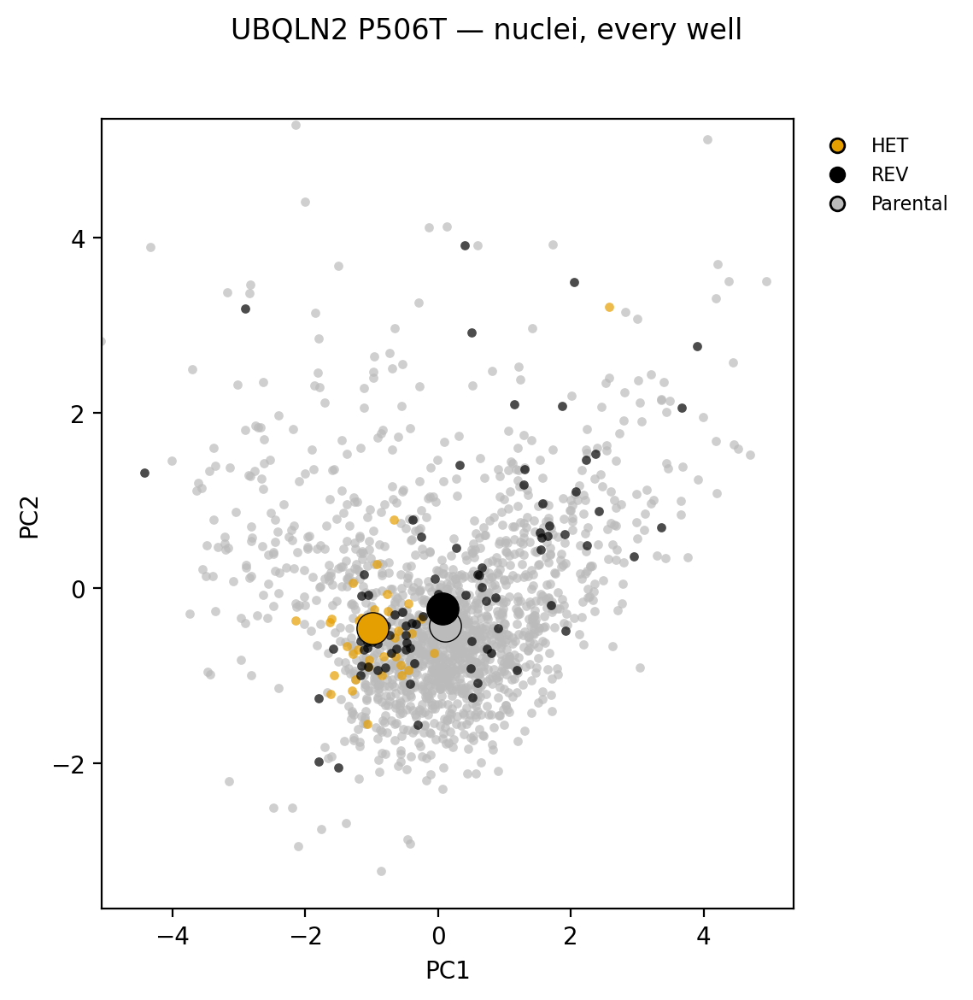

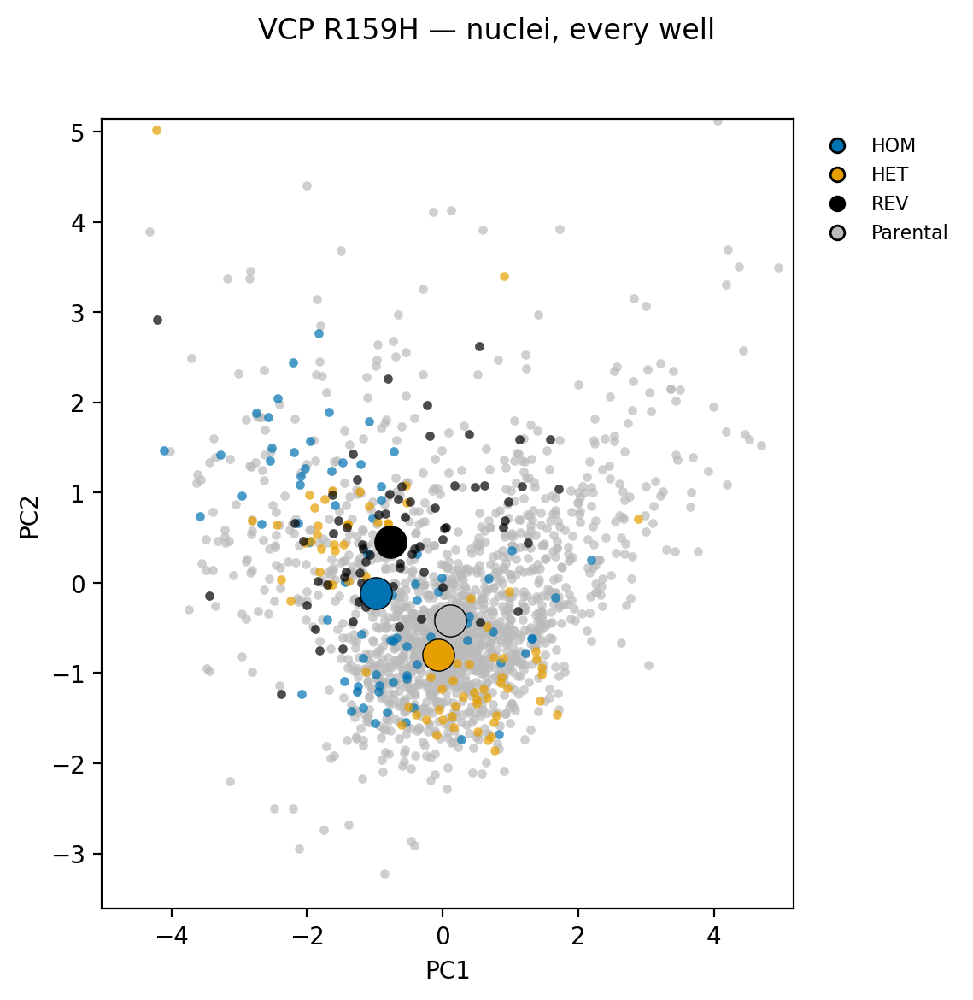

In [11]:
PARENTAL_NAME = "Parental"
GENO_COLORS = {"Parental": "#BBBBBB", "HET": "#E69F00", "HOM": "#0072B2",
               "REV": "#000000", "OTHER": "#F0E442"}
GENO_ORDER = ["HOM", "HET", "REV", "Parental"]

def _color_key(d):
    name = d["Genotype_Name"].astype(str).str.strip()
    is_par = name.str.upper() == PARENTAL_NAME.upper()
    zyg = name.str.split().str[-1].str.upper()
    return np.where(is_par, "Parental", zyg)

def variant_pca(df, gene, variant, pcx="PC1", pcy="PC2", parental=None,
                s=15, alpha=0.7, s_centroid=180, pad=1.5):
    src = df[(df["Gene"] == gene) & (df["Variant"] == variant)].copy()
    if parental is not None and not parental.empty:
        src = pd.concat([src, parental], ignore_index=True)
    if src.empty:
        print(f"[skip] no rows for {gene} {variant}"); return
    src["_ckey"] = _color_key(src)
    nonpar = src.loc[src["_ckey"] != "Parental", "_ckey"]
    note = "" if nonpar.isin(["HOM", "HET"]).any() else "  [revertant only]"

    px, py = src[pcx].dropna(), src[pcy].dropna()
    x_lo, x_hi = px.quantile(.01) - pad, px.quantile(.99) + pad
    y_lo, y_hi = py.quantile(.01) - pad, py.quantile(.99) + pad
    keys = [k for k in GENO_ORDER if k in src["_ckey"].unique()]
    draw = [k for k in keys if k == "Parental"] + [k for k in keys if k != "Parental"]

    fig, ax = plt.subplots(figsize=(6, 6), dpi=200)
    fig.subplots_adjust(right=0.80)
    for k in draw:
        gg = src[src["_ckey"] == k]
        ax.scatter(gg[pcx], gg[pcy], s=s, alpha=alpha,
                   color=GENO_COLORS.get(k, GENO_COLORS["OTHER"]),
                   linewidths=0, rasterized=True)
    for k in draw:
        gg = src[src["_ckey"] == k]
        if not gg.empty:
            ax.scatter(gg[pcx].median(), gg[pcy].median(), s=s_centroid,
                       color=GENO_COLORS.get(k, GENO_COLORS["OTHER"]),
                       edgecolor="k", linewidths=0.5, zorder=5)
    ax.set_xlim(x_lo, x_hi); ax.set_ylim(y_lo, y_hi)
    ax.set_xlabel(pcx); ax.set_ylabel(pcy)
    handles = [Line2D([0], [0], marker="o", linestyle="", markersize=6,
               markerfacecolor=GENO_COLORS.get(k, GENO_COLORS["OTHER"]),
               markeredgecolor="k", label=k) for k in keys]
    ax.legend(handles=handles, loc="upper left", bbox_to_anchor=(1.01, 1.0),
              frameon=False, fontsize=8)
    fig.suptitle(f"{gene} {variant} — nuclei, every well{note}", y=0.98)
    plt.show()

# driver
well_df = well_level
is_par = well_df["Genotype_Name"].astype(str).str.strip().str.upper() == PARENTAL_NAME.upper()
parental_all = well_df[is_par].copy()
variants = (well_df.loc[~is_par, ["Gene", "Variant"]]
            .dropna().drop_duplicates().sort_values(["Gene", "Variant"]))
for gene, variant in variants.itertuples(index=False):
    variant_pca(well_df, gene, variant, parental=parental_all)


MANUAL (2198 wells)


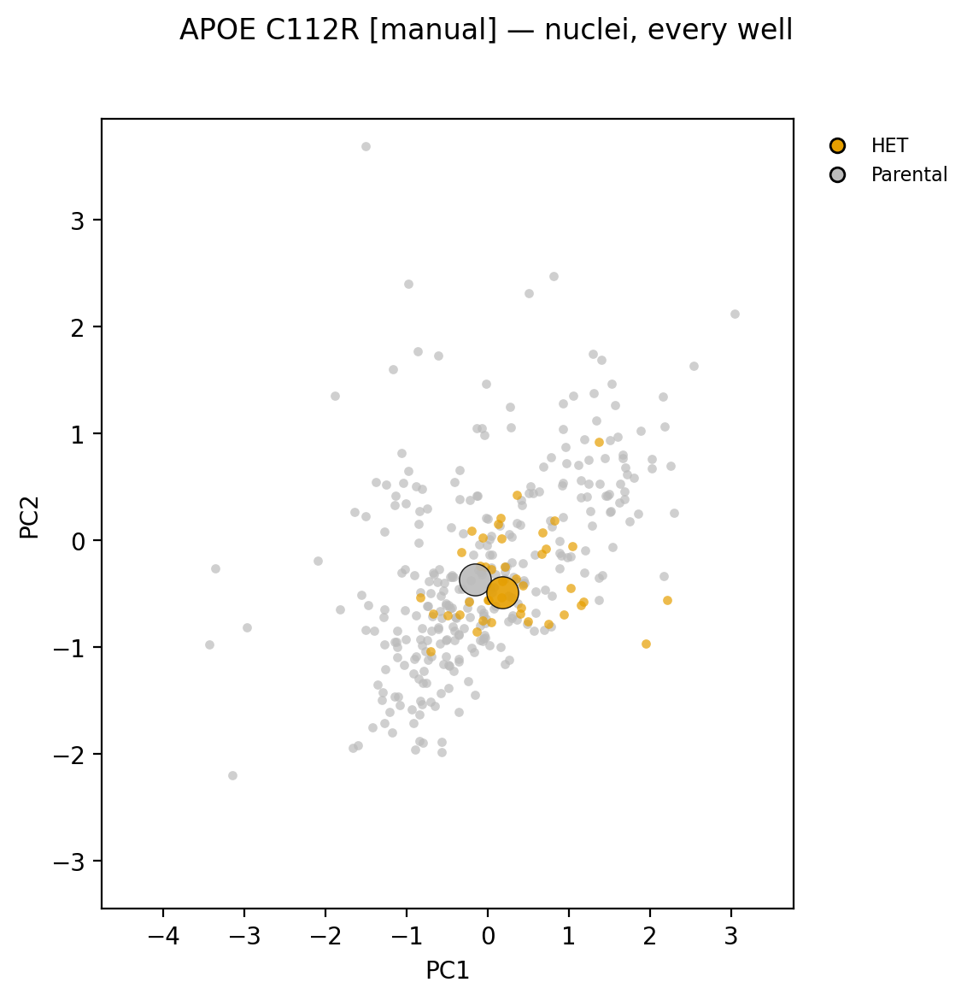

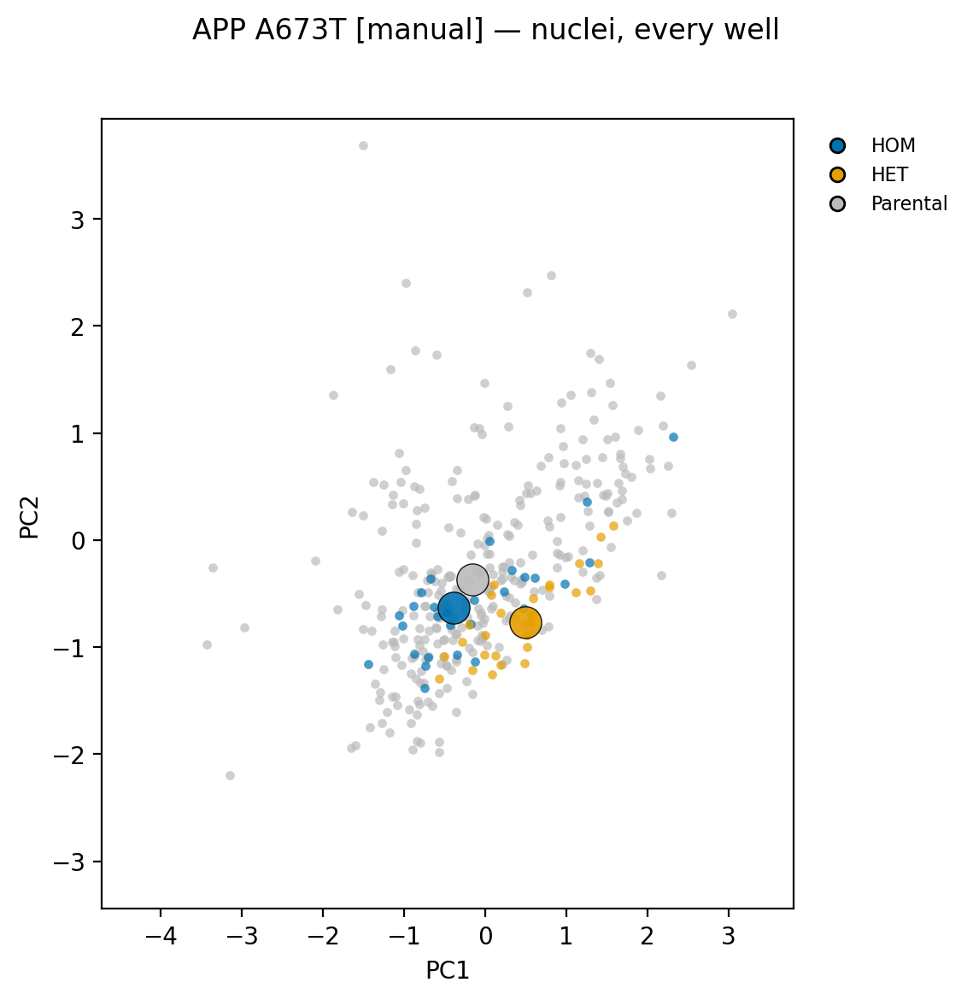

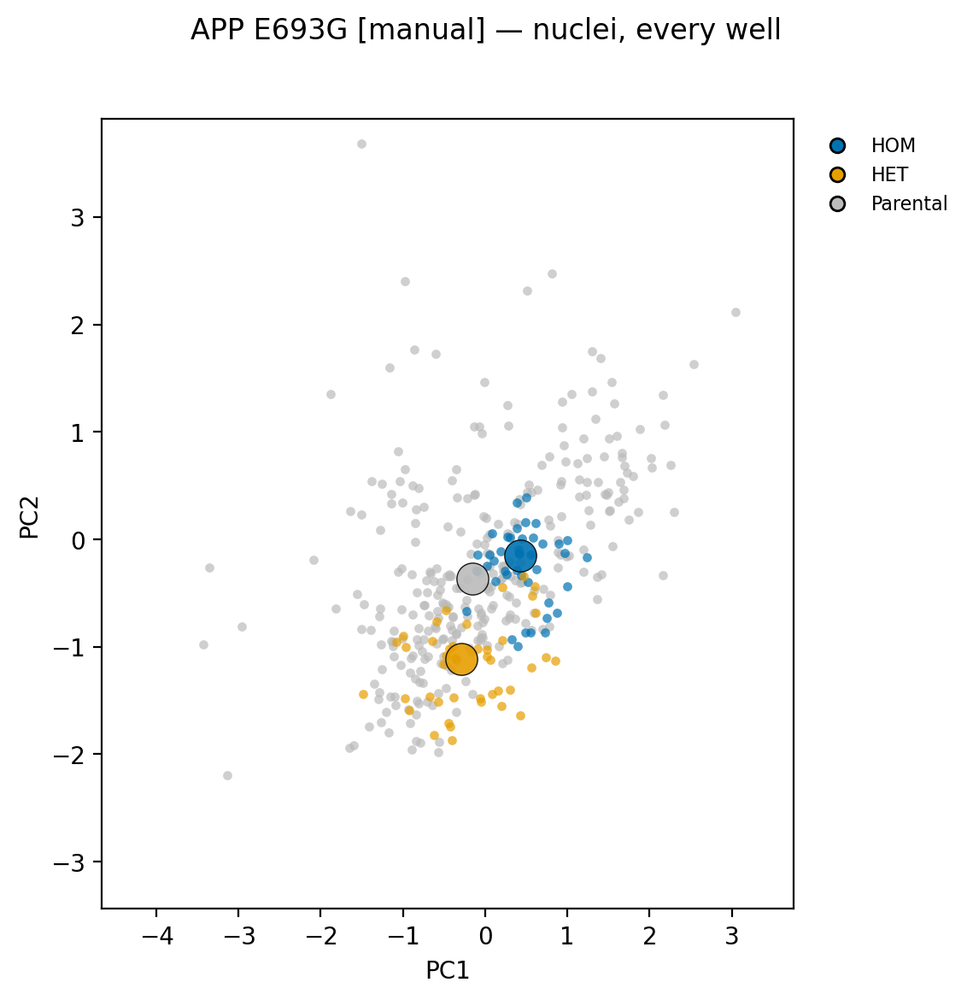

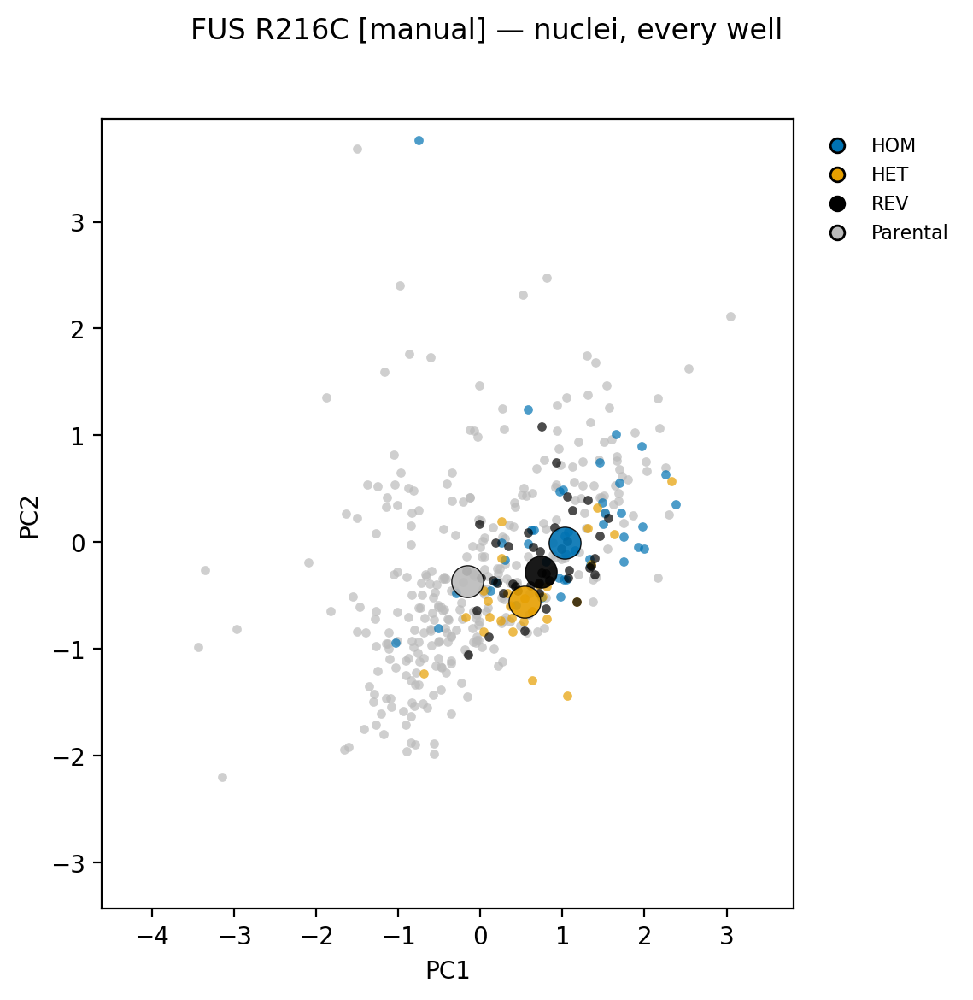

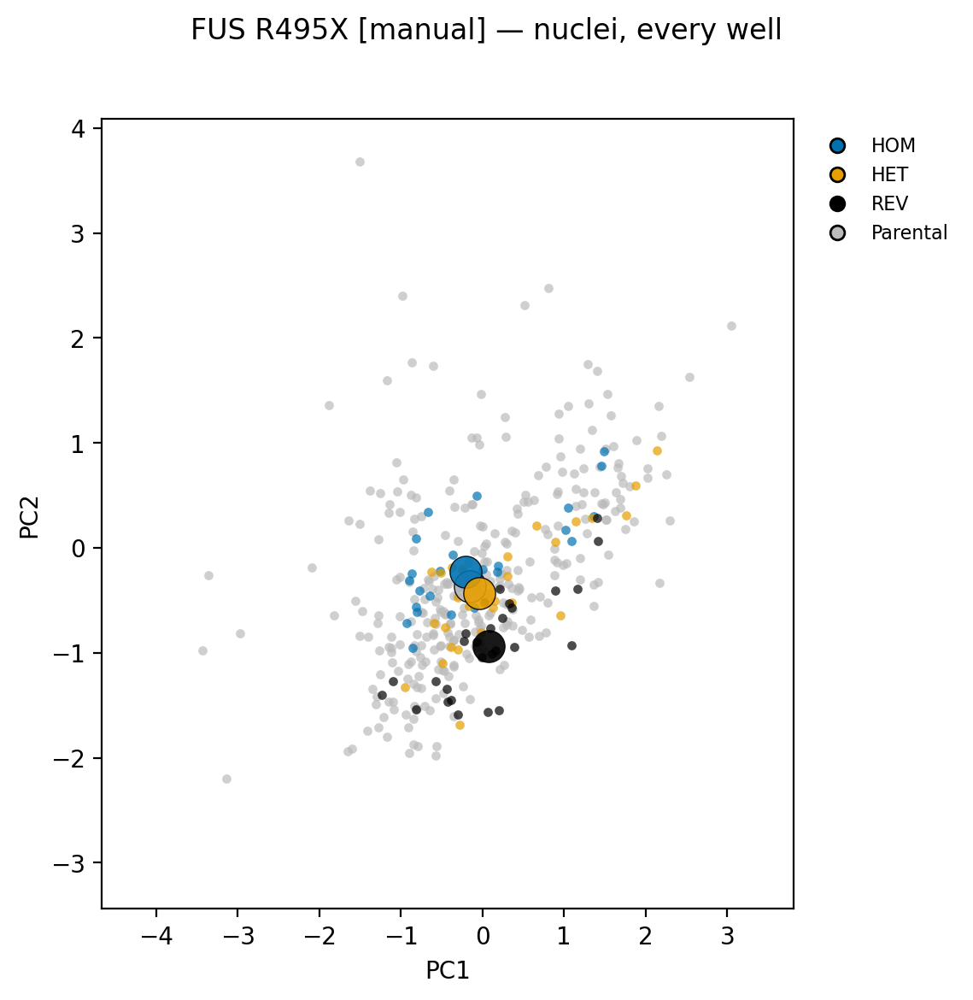

...

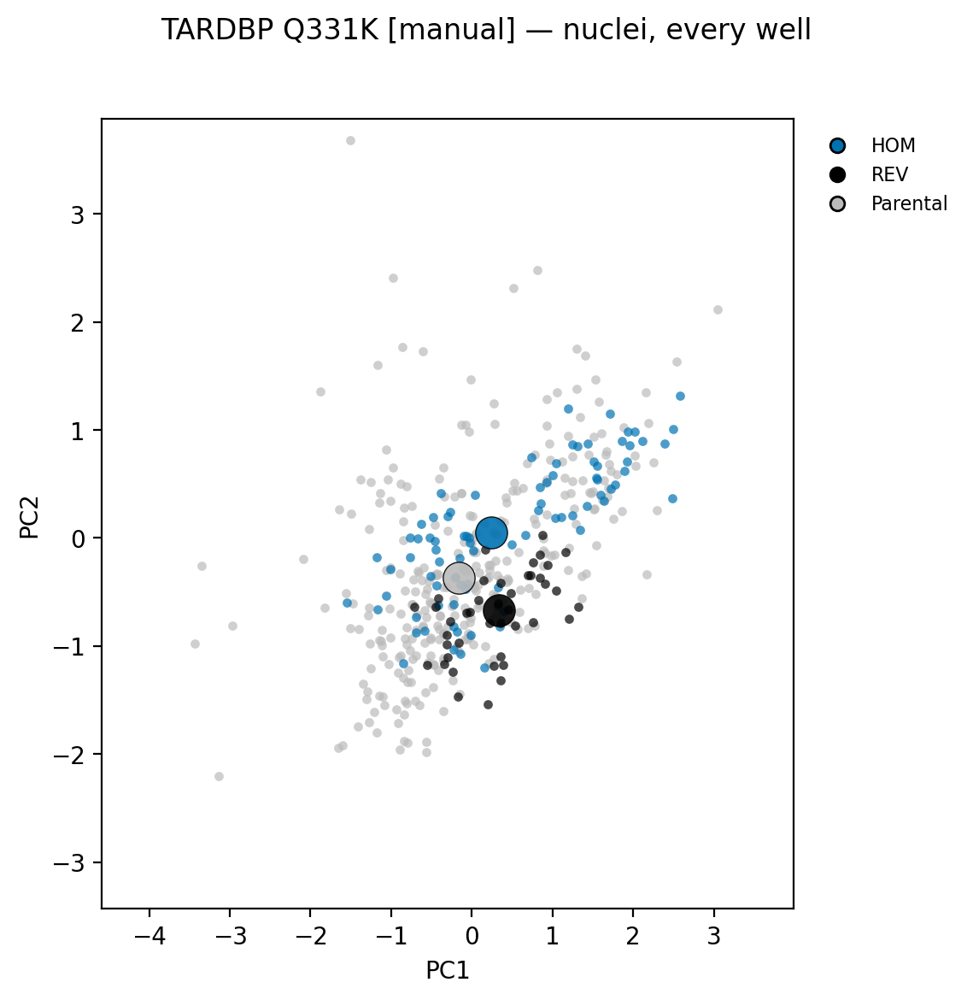

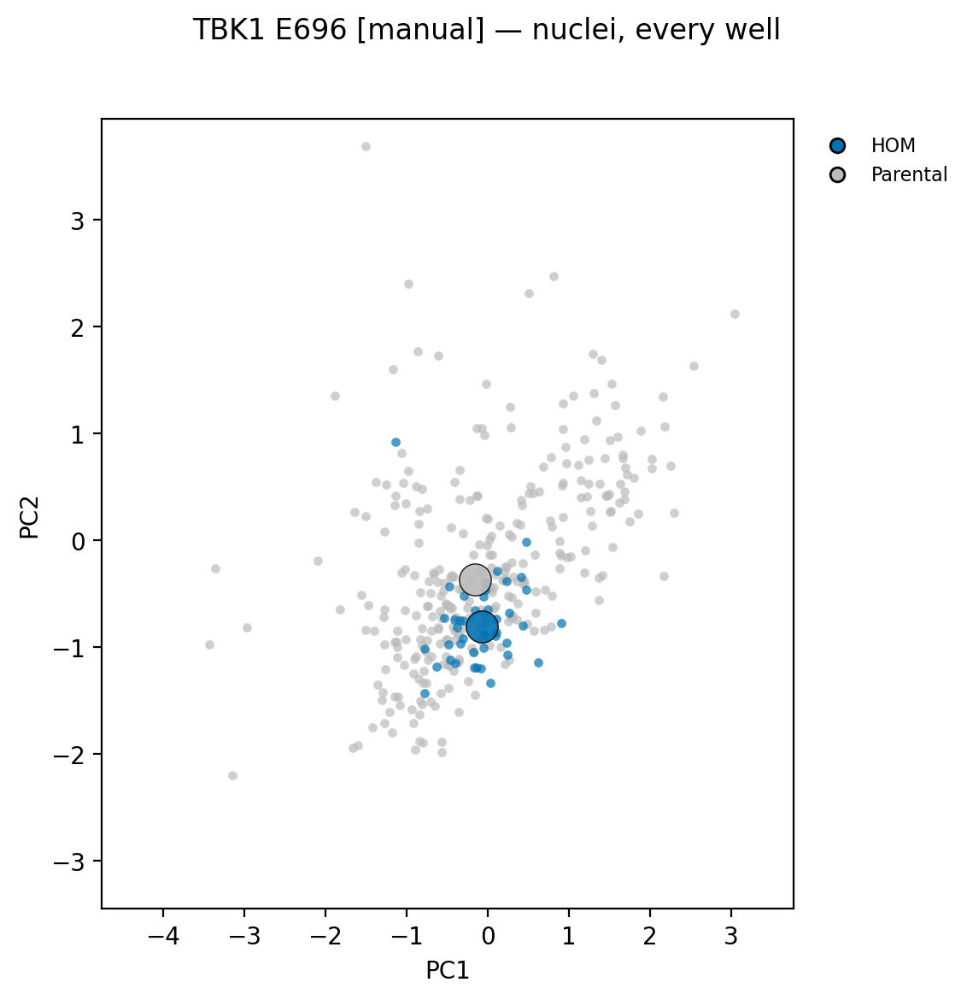

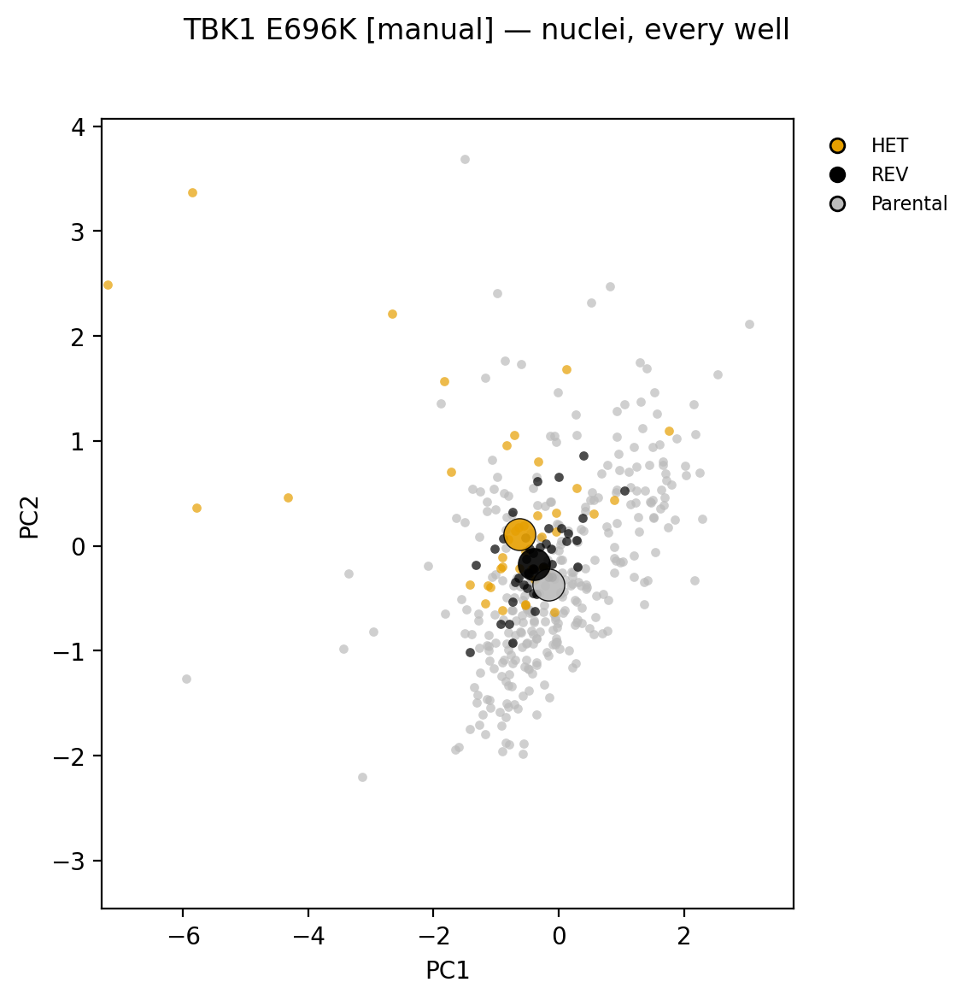

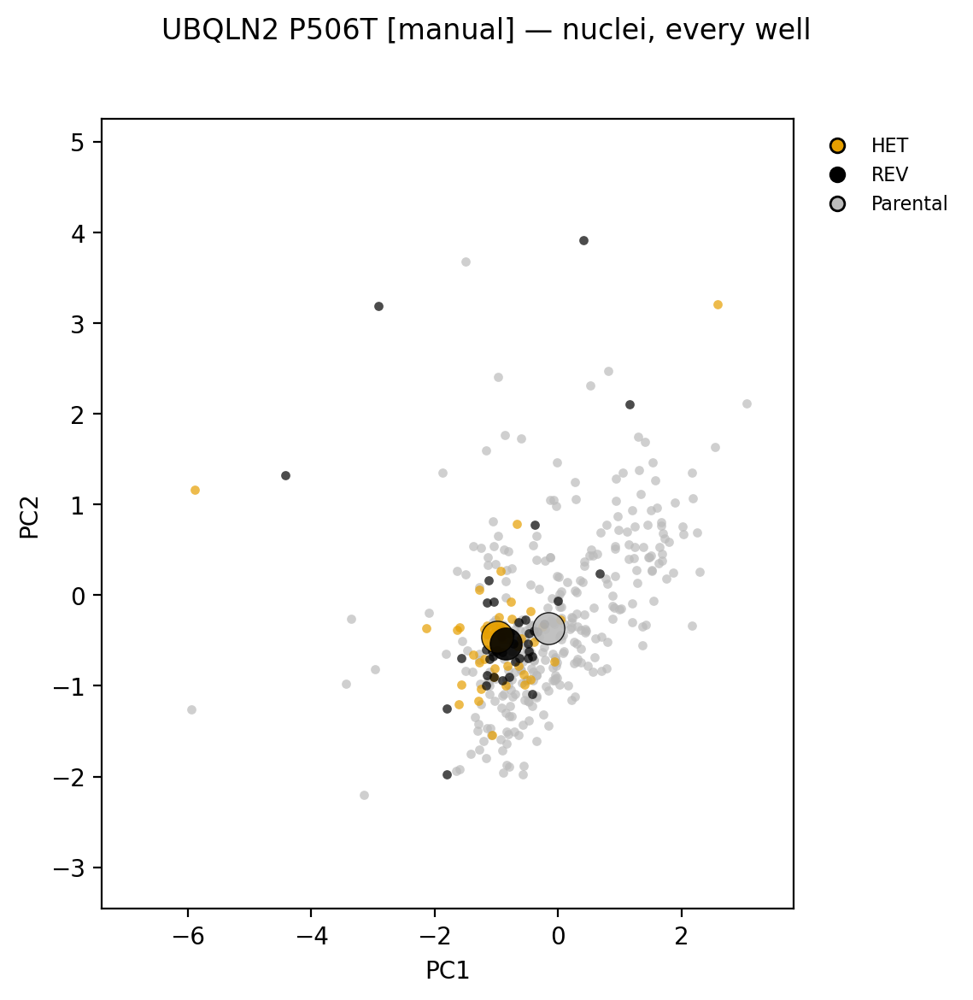

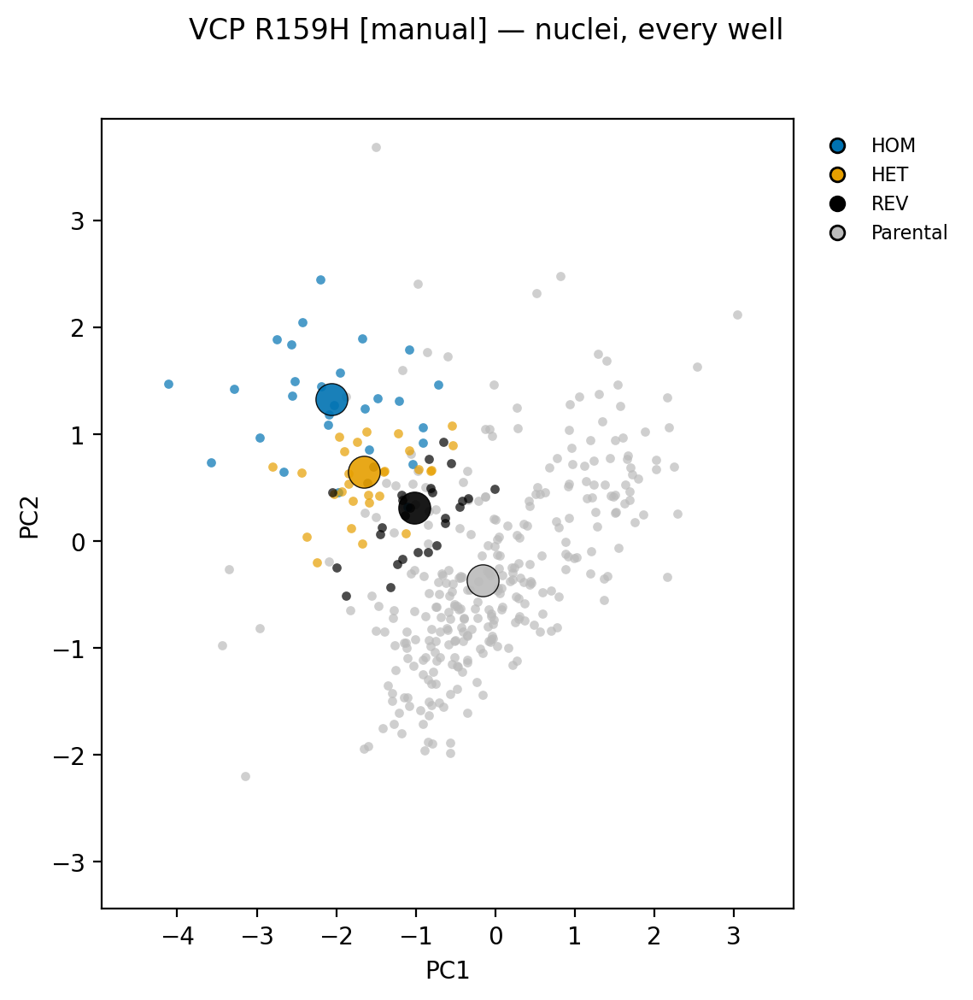


AUTOMATED (4159 wells)


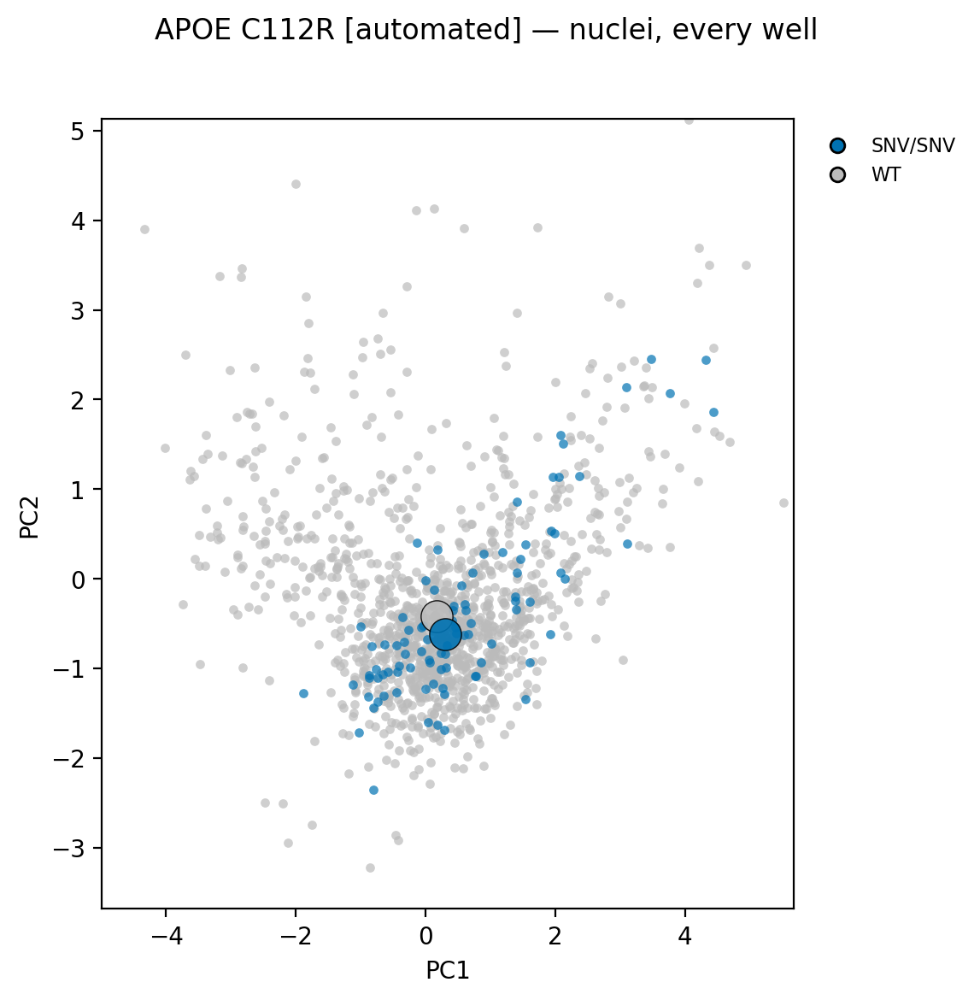

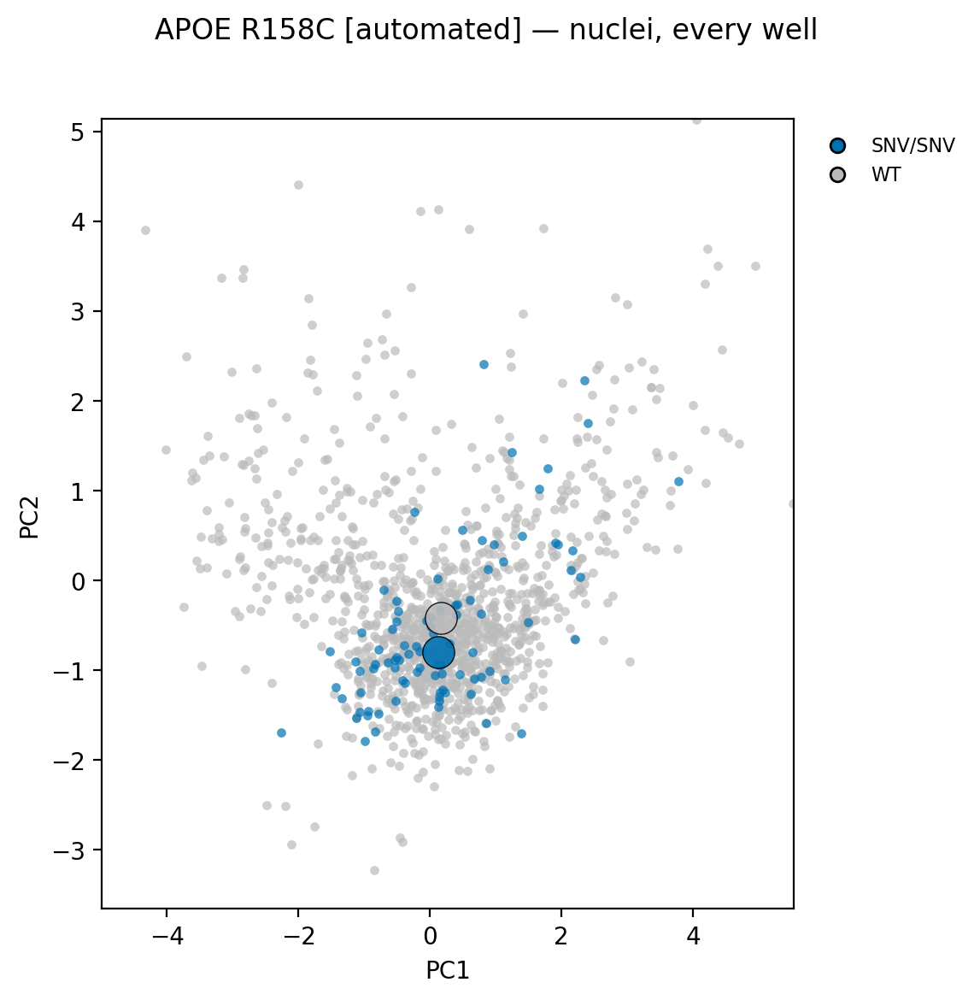

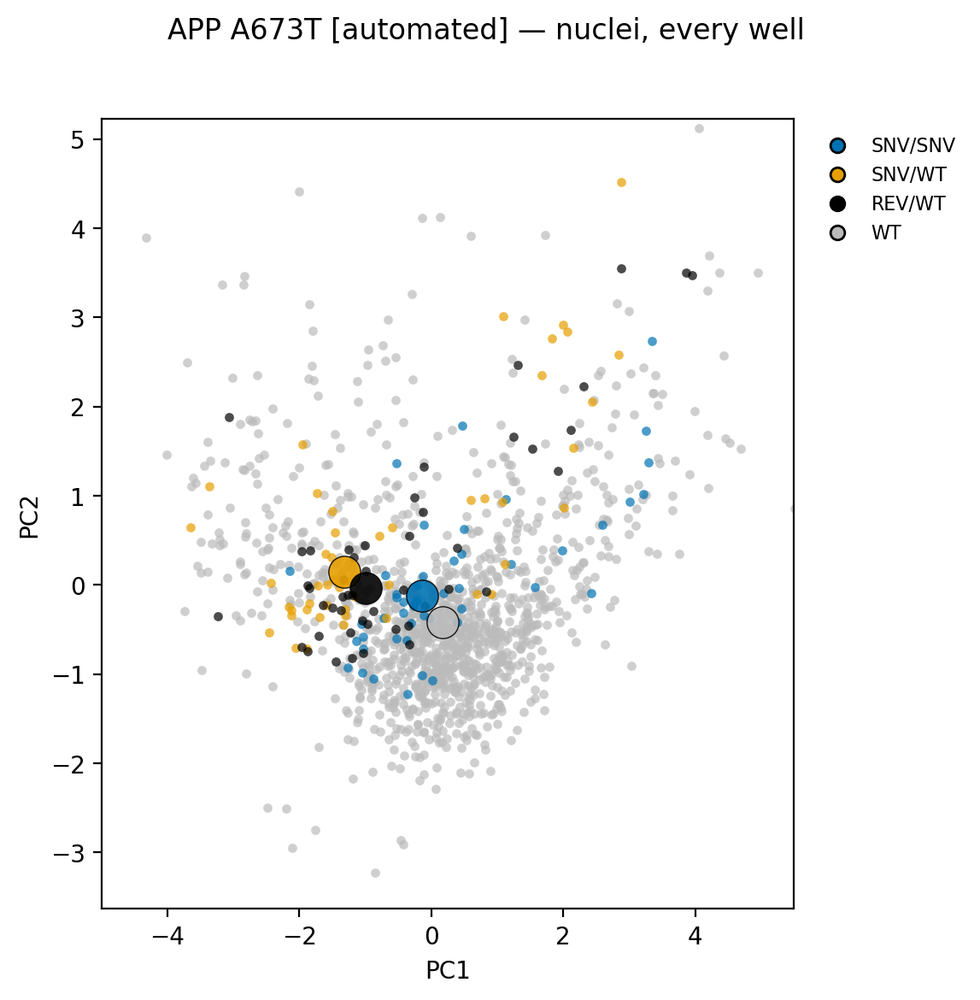

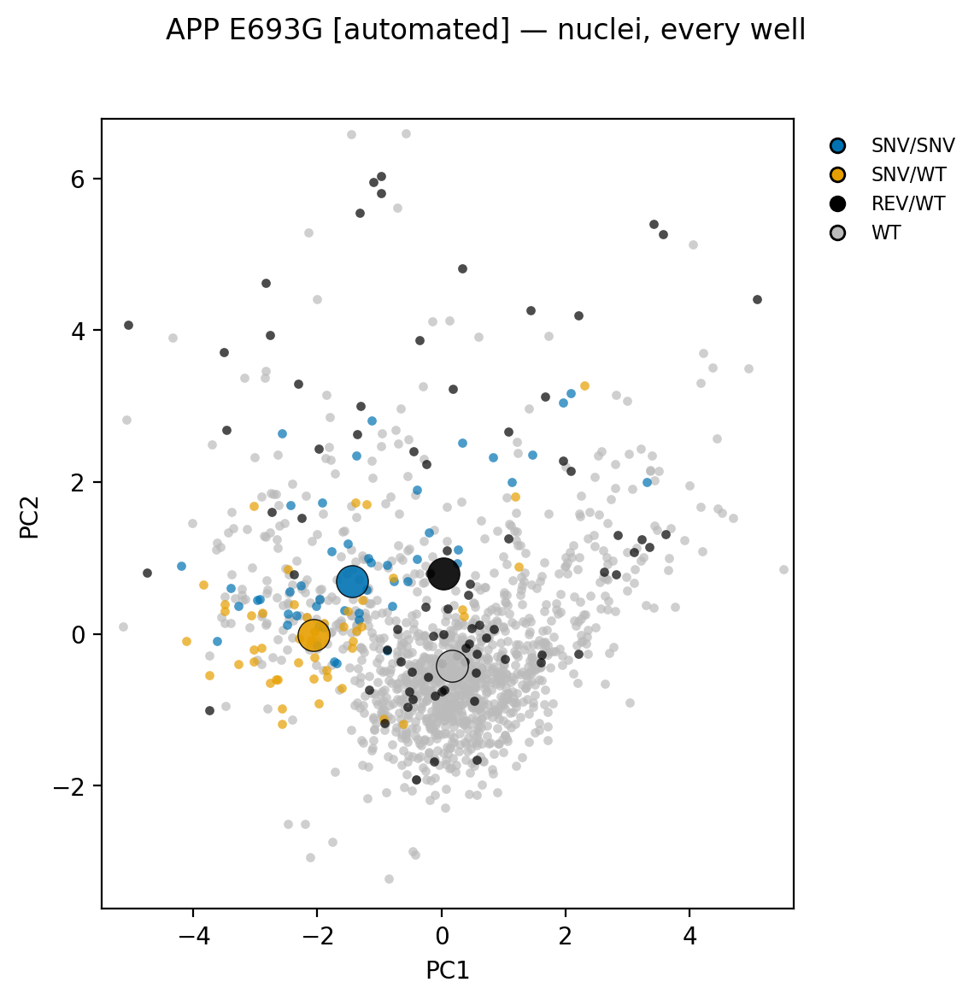

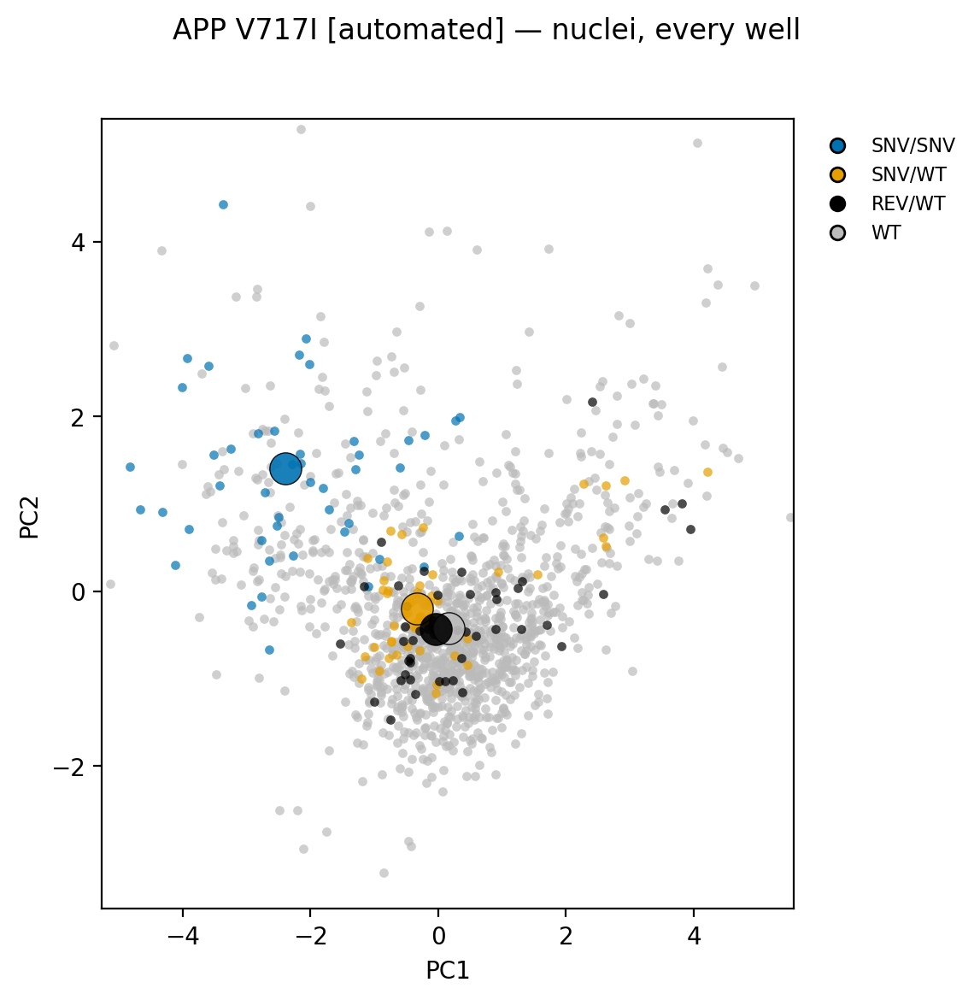

...

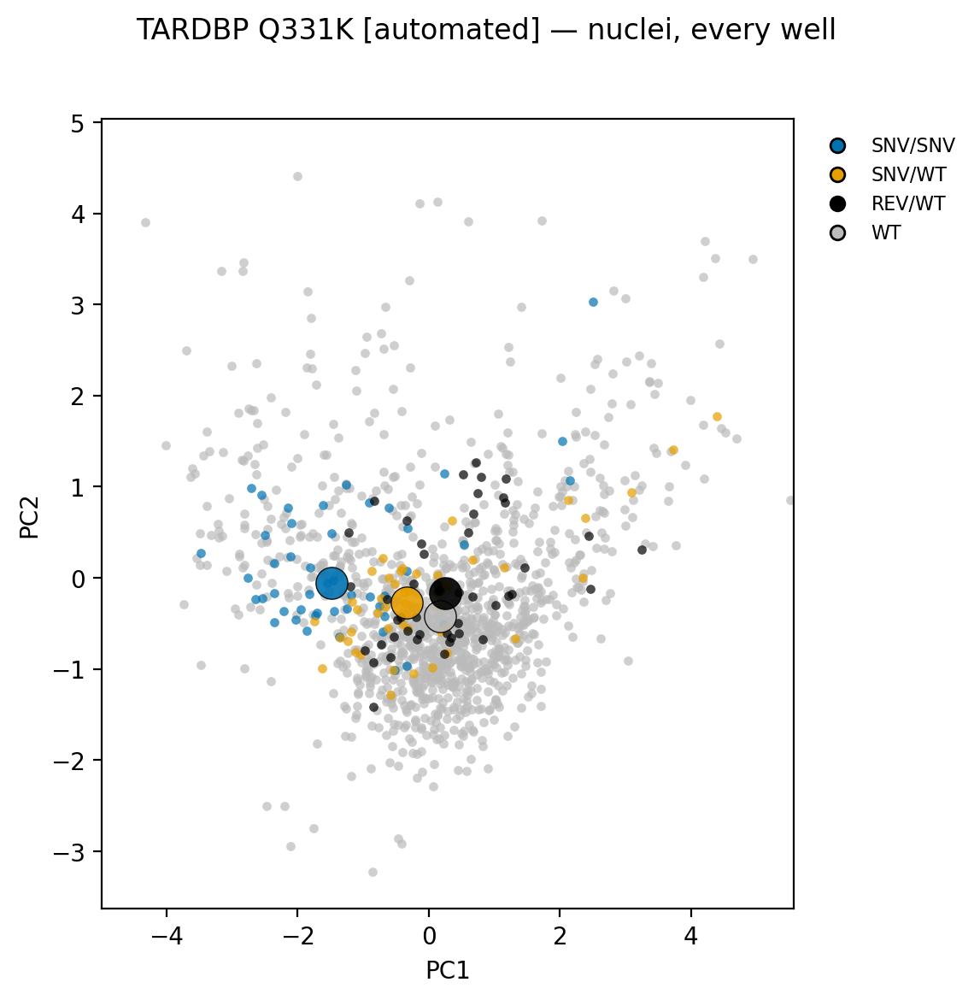

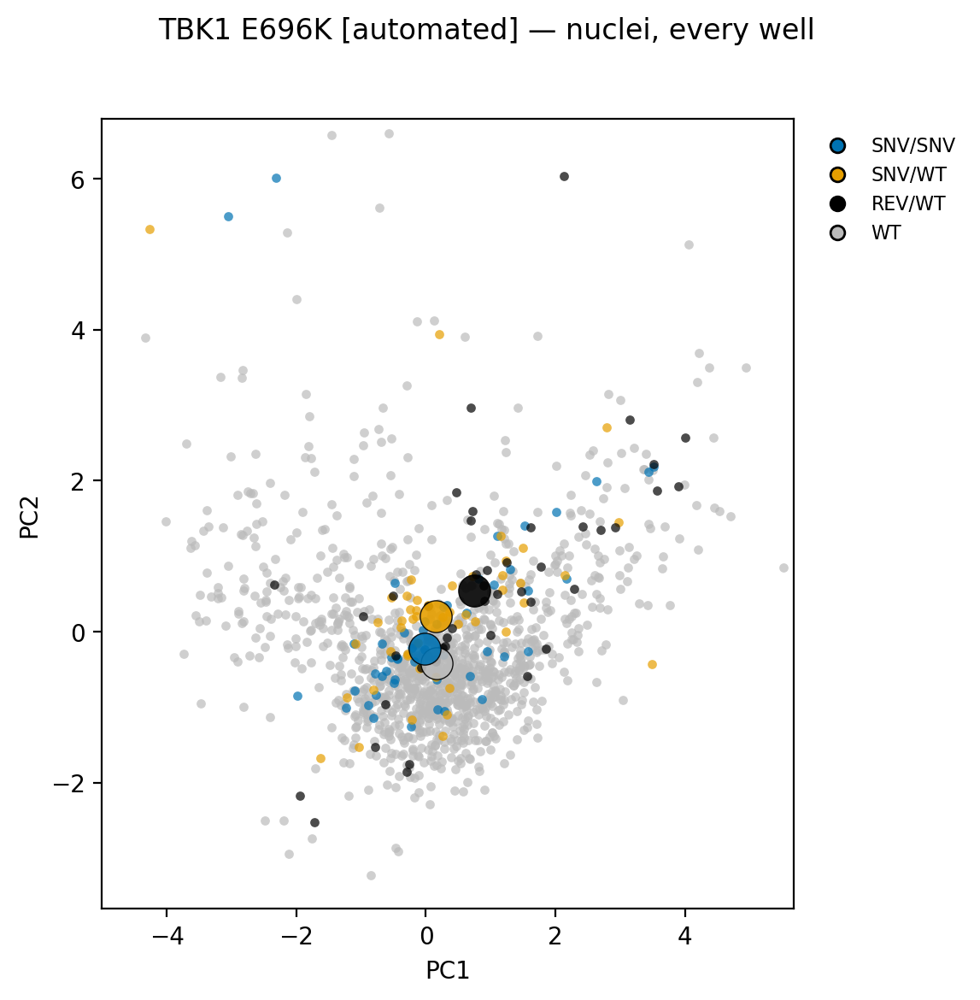

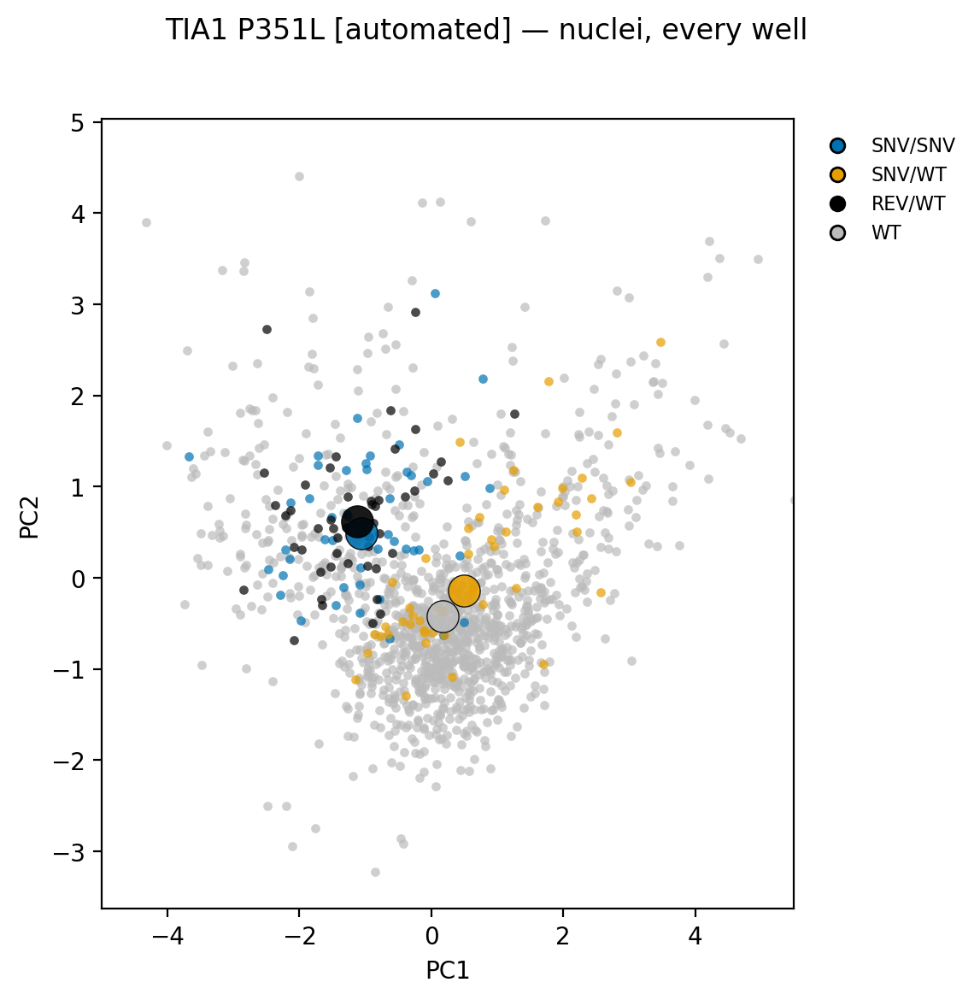

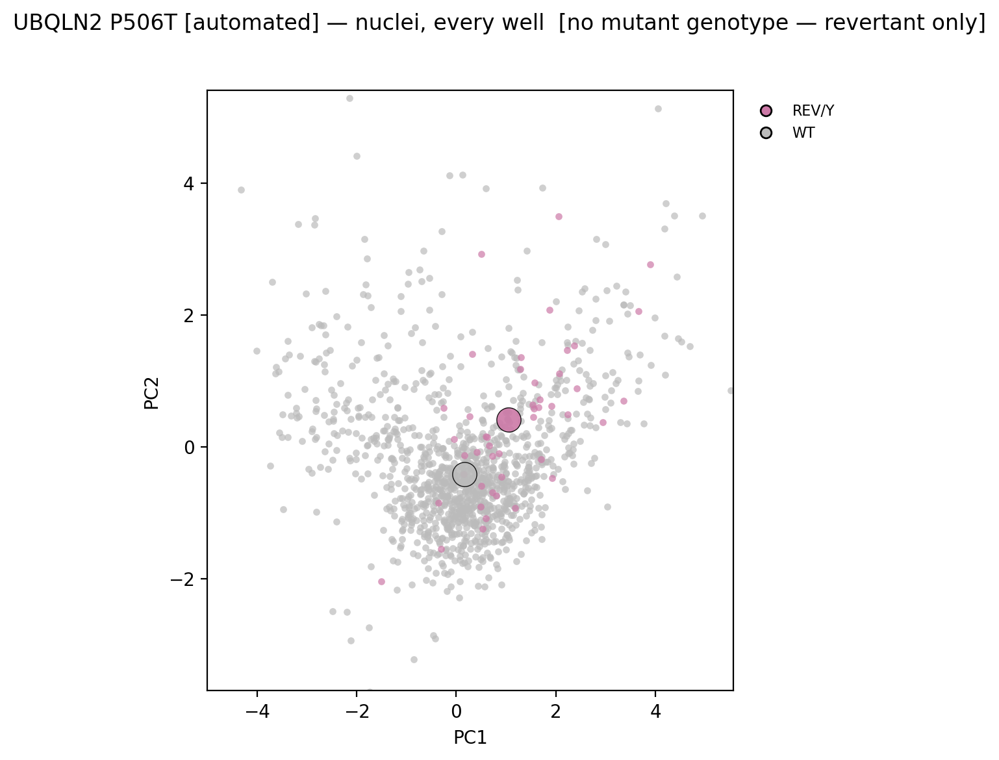

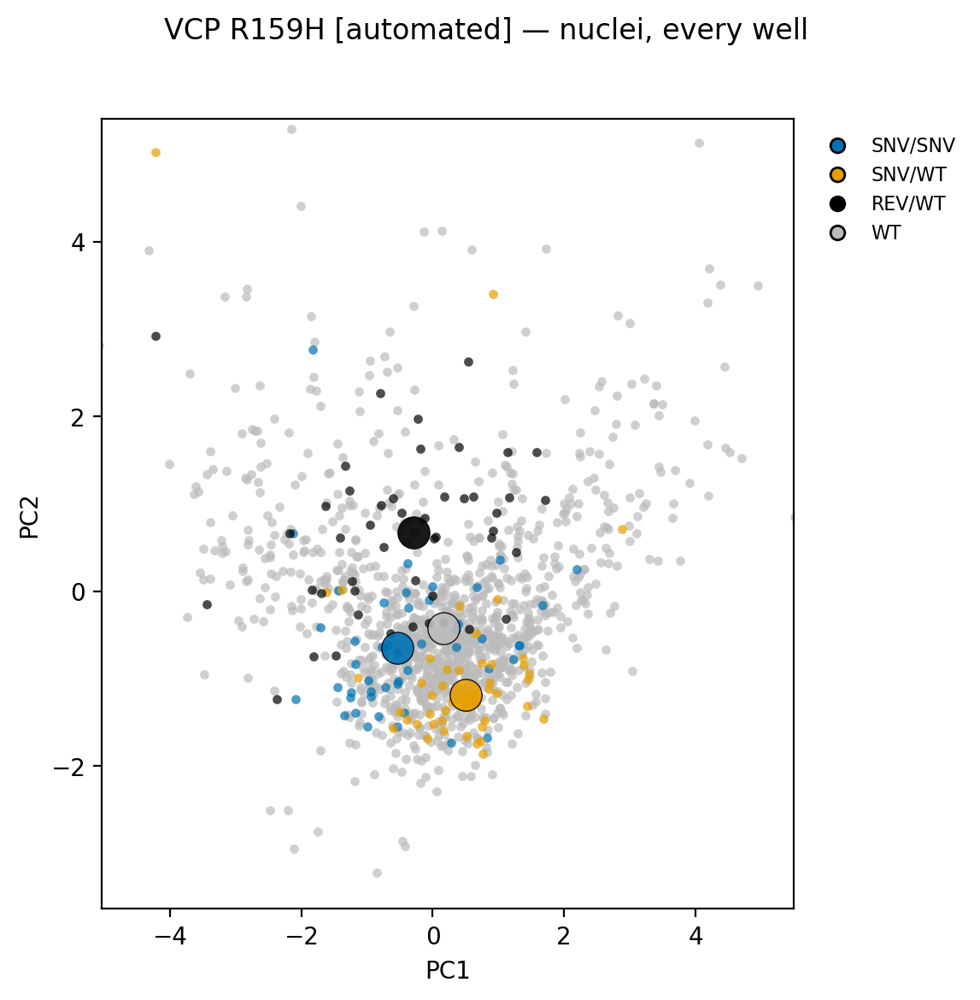

In [14]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D

# ==========================================================================
# Prep split
# ==========================================================================
PREP_COL = "prep_method"          # column tagging each well's prep
AUTOMATED_VAL = "automated"
MANUAL_VAL = "manual"

# ==========================================================================
# Group-specific schemes
# ==========================================================================
# --- Manual: parental by Genotype_Name == "Parental"; genotype is the trailing
#     token of Genotype_Name (HOM / HET / REV). -----------------------------
MANUAL_PARENTAL_NAME = "Parental"
MANUAL_COLORS = {
    "Parental": "#BBBBBB", "HET": "#E69F00", "HOM": "#0072B2",
    "REV": "#000000", "OTHER": "#F0E442",
}
MANUAL_ORDER = ["HOM", "HET", "REV", "Parental"]
MANUAL_PARENTAL_KEY = "Parental"

def _manual_is_parental(df):
    return (df["Genotype_Name"].astype(str).str.strip().str.upper()
            == MANUAL_PARENTAL_NAME.upper())

def _manual_color_key(df):
    name = df["Genotype_Name"].astype(str).str.strip()
    zyg = name.str.split().str[-1].str.upper()        # HOM / HET / REV
    return np.where(_manual_is_parental(df), MANUAL_PARENTAL_KEY, zyg)

def _manual_has_mutant(nonpar_keys):
    return nonpar_keys.isin(["HOM", "HET"]).any()

# --- Automated: parental by Gene == "KOLF2.1J"; genotype from the Genotype
#     column (SNV/SNV, SNV/WT, SNV/Y, ...). ---------------------------------
AUTO_WT_GENE = "KOLF2.1J"
AUTO_COLORS = {
    "WT": "#BBBBBB", "SNV/WT": "#E69F00", "SNV/SNV": "#0072B2",
    "REV/WT": "#000000", "SNV/Y": "#009E73", "REV/Y": "#CC79A7",
    "OTHER": "#F0E442",
}
AUTO_ORDER = ["SNV/SNV", "SNV/WT", "SNV/Y", "REV/WT", "REV/Y", "WT"]
AUTO_PARENTAL_KEY = "WT"

def _auto_is_parental(df):
    return (df["Gene"].astype(str).str.strip().str.upper()
            == AUTO_WT_GENE.upper())

def _auto_color_key(df):
    return np.where(_auto_is_parental(df), AUTO_PARENTAL_KEY,
                    df["Genotype"].astype(str).str.strip())

def _auto_has_mutant(nonwt_keys):
    return nonwt_keys.str.startswith("SNV").any()

SCHEMES = {
    "manual": {
        "label": "manual", "is_parental": _manual_is_parental,
        "color_key": _manual_color_key, "colors": MANUAL_COLORS,
        "order": MANUAL_ORDER, "parental_key": MANUAL_PARENTAL_KEY,
        "has_mutant": _manual_has_mutant,
    },
    "automated": {
        "label": "automated", "is_parental": _auto_is_parental,
        "color_key": _auto_color_key, "colors": AUTO_COLORS,
        "order": AUTO_ORDER, "parental_key": AUTO_PARENTAL_KEY,
        "has_mutant": _auto_has_mutant,
    },
}


# ==========================================================================
# Figure: single-panel PCA for one allele (nucleus-level, no faceting)
# ==========================================================================
def variant_pca(
    df, gene, variant, scheme, pcx="PC1", pcy="PC2", title=None, pad=1.5,
    parental=None, s=15, alpha=0.7, s_centroid=180, figsize=(6, 6),
):
    """Single PCA panel for one (gene, variant), using `scheme` for color keys,
    palette, and ordering. `parental` is the pooled parental reference."""
    colors = scheme["colors"]
    order = scheme["order"]
    par_key = scheme["parental_key"]

    src = df[(df["Gene"] == gene) & (df["Variant"] == variant)].copy()
    if parental is not None and not parental.empty:
        src = pd.concat([src, parental], ignore_index=True)
    if src.empty:
        print(f"[skip] ({scheme['label']}) no rows for {gene} {variant}")
        return None

    src["_ckey"] = scheme["color_key"](src)

    nonpar = src.loc[src["_ckey"] != par_key, "_ckey"]
    has_mutant = scheme["has_mutant"](nonpar)
    mutant_note = "" if has_mutant else "  [no mutant genotype — revertant only]"

    px, py = src[pcx].dropna(), src[pcy].dropna()
    if px.empty or py.empty:
        print(f"[skip] ({scheme['label']}) no finite PC values for {gene} {variant}")
        return None
    x_lo, x_hi = px.quantile(.01) - pad, px.quantile(.99) + pad
    y_lo, y_hi = py.quantile(.01) - pad, py.quantile(.99) + pad

    all_keys = list(pd.unique(src["_ckey"]))
    unknown = [k for k in all_keys if k not in colors]
    if unknown:
        print(f"[warning] ({scheme['label']}) {gene} {variant}: genotype(s) "
              f"not in palette, drawn as OTHER: {unknown}")
    keys_present = ([k for k in order if k in all_keys]
                    + [k for k in all_keys if k not in order])
    draw_order = ([k for k in keys_present if k == par_key]
                  + [k for k in keys_present if k != par_key])

    fig, ax = plt.subplots(figsize=figsize, dpi=200)
    fig.subplots_adjust(right=0.80)

    for k in draw_order:                        # clouds: parental bottom
        gg = src[src["_ckey"] == k]
        ax.scatter(gg[pcx], gg[pcy], s=s, alpha=alpha,
                   color=colors.get(k, colors["OTHER"]),
                   linewidths=0, rasterized=True)
    for k in draw_order:                         # centroids
        gg = src[src["_ckey"] == k]
        if gg.empty:
            continue
        ax.scatter(gg[pcx].median(), gg[pcy].median(), s=s_centroid,
                   color=colors.get(k, colors["OTHER"]),
                   edgecolor="k", linewidths=0.5, alpha=0.9, zorder=5)

    ax.set_xlim(x_lo, x_hi); ax.set_ylim(y_lo, y_hi)
    ax.set_xlabel(pcx); ax.set_ylabel(pcy)

    handles = [
        Line2D([0], [0], marker="o", linestyle="", markersize=6,
               markerfacecolor=colors.get(k, colors["OTHER"]),
               markeredgecolor="k", label=k)
        for k in keys_present
    ]
    ax.legend(handles=handles, loc="upper left", bbox_to_anchor=(1.01, 1.0),
              frameon=False, fontsize=8)

    fig.suptitle((title or f"{gene} {variant} [{scheme['label']}] — nuclei, "
                  f"every well") + mutant_note, y=0.98)
    plt.show()
    return fig


# ==========================================================================
# Driver: run each prep group independently with its own scheme.
# ==========================================================================
def run_group(well_df, scheme):
    print(f"\n{'=' * 60}\n{scheme['label'].upper()} ({len(well_df)} wells)\n{'=' * 60}")

    is_par = scheme["is_parental"](well_df)
    parental_all = well_df[is_par].copy()

    variants = (well_df.loc[~is_par, ["Gene", "Variant"]]
                .dropna().drop_duplicates().sort_values(["Gene", "Variant"]))

    for gene, variant in variants.itertuples(index=False):
        variant_pca(well_df, gene, variant, scheme, parental=parental_all)


well_df = well_level

# Manual-only fixup from the previous manual driver.
well_df.loc[
    well_df["Genotype_Name"].astype(str).str.strip() == "TBK1 E696K HOM",
    "Variant",
] = "E696K"

prep = well_df[PREP_COL].astype(str).str.strip().str.lower()

run_group(well_df[prep == MANUAL_VAL.lower()].copy(),    SCHEMES["manual"])
run_group(well_df[prep == AUTOMATED_VAL.lower()].copy(), SCHEMES["automated"])